# Revised four research questions and extension of the completed pilot

This version extends the completed pilot after supervisor feedback. Original results are retained with legacy identifiers RQ1–RQ4 for traceability; these identifiers do not all match the revised RQ numbering. The mapping below is authoritative.

1. **Revised RQ1 — Decision context:** Under what combinations of error and deferral costs do confidence-based and cost-aware policies prescribe different actions for identical model predictions, and how do these differences affect decision loss and automated coverage?
2. **Revised RQ2 — Uncertainty in evidence:** How does finite-sample uncertainty in estimated predictive reliability affect the stability of reliance decisions, and when does incorporating that uncertainty improve decisions compared with point estimates alone?
3. **Revised RQ3 — Distribution shift:** Under what changes in population composition does a previously validated reliance policy become unreliable, and to what extent can recalibration restore its decision performance without retraining?
4. **Revised RQ4 — Subgroup burdens and limited review:** When does abstention reduce automated prediction error while increasing subgroup disparities in deferral burden, and how do limited review capacity and imperfect fallback decisions affect this trade-off?

| Revised RQ | Existing pilot evidence retained | New result objects |
|---|---|---|
| RQ1 | Legacy RQ1 cost map, policy comparison and same-case reversals | Existing evidence retained; no new method is claimed from renaming it |
| RQ2 | Legacy RQ2 subgroup audit and RQ3 calibration-size sensitivity are supporting context | UQ_F1 evidence-size loss and coverage; UQ_F2 action changes; UQ_T1 point-versus-interval policy audit; UQ_T2 evidence-size and scenario sensitivity |
| RQ3 | Legacy RQ3 ACS transport, recalibration and constructed UCI composition shift | Existing evidence retained |
| RQ4 | Legacy RQ4 imperfect fallback and aggregate capacity; legacy RQ2 subgroup audit | GB_F1 review burden versus capacity; GB_F2 group loss versus capacity; GB_T1 group capacity/fallback audit; GB_T2 between-sex gap audit |

**New RQ2 design:** fix logistic regression in advance; fit on the original training partition. Partition the original calibration pool by household/profile into sigmoid-fitting and independent reliability-evidence halves. Do not select this model or policy using validation/test outcomes. Use five fixed probability bins. Estimate each bin's positive-label frequency from evidence records and construct conservative cluster-weighted Hoeffding bounds with a five-bin union adjustment. Bounds concern bin-average label rates, not individual probabilities. Compare actions minimizing point-estimated loss with actions minimizing worst-case loss over each bin interval. Repeat nested evidence subsampling using whole clusters. Deferral is an idealized total-cost alternative in this experiment.

**New RQ4 design:** retain the source-selected models and validation-selected thresholds from the pilot. For each capacity and explicitly assumed fallback-error setting, allocate review across the complete test batch before computing group summaries. Report requested referrals, actual review, unmet referrals, automated error, expected system loss and between-sex gaps. Review capacity is shared across groups. Include recorded race categories in the full audit but avoid strong sparse-group comparisons.

**Interpretation:** these additions test revised RQs with explicit operationalizations. They do not establish novelty, measure psychological trust, or prove moral permissibility. The philosophical contribution and journal submission readiness require separate assessment. This is an exploratory revision after examining pilot data; it must not be described as a preregistered confirmatory study.

**Retained pilot description. The revised RQs and mapping above supersede the original numbering. The complete revised run produces 24 primary result objects.**

# When calibrated confidence warrants reliance on AI
## Project 15 — reproducible experiments for Minds and Machines

**Purpose.** Test the empirical boundaries of a proposed account of warranted reliance using UCI credit-card default and ACSIncome. This notebook produces **16 planned primary result objects: eight figures and eight tables, four per research question**, plus supporting audits, predictions and sensitivity analyses. All numerical results are generated by code from real public records; error costs, review errors and review capacity are explicitly constructed scenarios.

**Anchor:** Andrea Ferrario (2026; online 2025), *Being Pragmatic About Reliance and Trust in Artificial Intelligence*, https://doi.org/10.1007/s11023-025-09754-9. The paper treats appropriateness, efficiency and objective reasons as expectations of reliance. This notebook is an extension, not a reproduction of experiments from that conceptual paper. The supplied attachment was the project catalogue; the anchor article was consulted at its publisher URL.

**Journal contribution.** Develop and defend a conditional account: predictive reliability is evidence relevant to reliance, but its practical force depends on the action, the evidence's reference population, its transportability, and the available alternative. Expected-loss minimization operationalizes one instrumental consideration; it does not establish moral permissibility or define epistemic warrant by itself. Numerical counterexamples constrain the argument, which must also address objections and competing accounts.

**Honesty boundary.** No notebook can guarantee novelty or acceptance. Calibration for decision-making and selective classification already exist. The potential contribution is the philosophical synthesis and its explicitly tested boundaries, not the invention of cost-sensitive classification. These benchmarks do not measure human reliance, psychological trust, institutional responsibility, causal harms or moral deservingness.

**Kaggle:** upload this `.ipynb`, select CPU and turn Internet **on**, then Run All. No GPU, credentials or paid APIs are required. Defaults use 3 split seeds, bounded ACS samples, 300 cluster-bootstrap replications and fixed baseline settings. To use attached offline data, put the original UCI ZIP/XLS/XLSX and Census ZIP/CSV files in `/kaggle/input`; the loader searches recursively. Internet is needed only for missing data and `xlrd` if absent. Results go to `/kaggle/working/warranted_reliance_results`; the final cell creates `warranted_reliance_results.zip` and a clickable download link.

## Research questions and planned results

| RQ | Question | Four planned primary result objects |
|---|---|---|
| RQ1 | Under what conditions does calibrated confidence provide epistemic grounds for reliance, and when do stakes and alternatives require different actions? | F1 reliability diagrams; F2 stakes–deferral policy advantage map; T1 held-out policy loss and paired differences; T2 same-confidence action reversals across decision contexts. |
| RQ2 | What subgroup evidence is required before population-level calibration justifies a shared reliance policy? | F3 subgroup reliability diagrams; F4 subgroup error–coverage profiles; T3 subgroup evidence audit with uncertainty and evidence flags; T4 shared versus group-informed thresholds. |
| RQ3 | When do changed deployment conditions undermine earlier evidence for reliance, and what evidence can restore it? | F5 natural ACS transport and recalibration losses; F6 UCI constructed population-mix sensitivity; T5 source/target calibration and decision audit; T6 target-recalibration sample-size sensitivity. |
| RQ4 | When does abstention improve a decision procedure, and when does its apparent benefit depend on unsupported fallback assumptions? | F7 fallback reliability–cost map; F8 policy system loss across fallback error assumptions; T7 policy performance under an explicitly imperfect fallback; T8 capacity-limited review sensitivity. |

Each figure is a single multi-panel publication-format object with PDF and PNG versions and its underlying CSV. Every planned table is displayed fully and exported as CSV and typeset PDF. Supporting tables are additional outputs. Planned outputs are analysis specifications, not predictions of statistically significant findings. Natural-shift RQ3 uses ACS only; UCI RQ3 is explicitly constructed reweighting, not observed temporal deployment.

## Step-by-step methodology

- **M1 — Fix the conceptual and empirical scope.** State the four RQs, distinguish probability calibration from Ferrario's broader calibration of reliance, and specify the proposed philosophical account before interpreting results.
- **M2 — Acquire and audit data.** Download authoritative UCI and Census releases; record URLs, hashes, sample counts, filters, feature roles and software versions. Use ACSIncome's published filter and nominal income threshold; exclude outcome and identifiers from predictors. Analyze both datasets separately.
- **M3 — Prevent leakage.** Partition source data into approximately 50% training, 20% probability calibration, 10% policy validation and 20% locked testing. Keep ACS households together; keep identical UCI feature profiles together. Repeat with seeds 42, 43 and 44. Reserve all target-domain labels from source model and policy selection.
- **M4 — Fit fixed baselines and calibrate.** Fit logistic regression and a random forest with training-only preprocessing; fit sigmoid recalibration on calibration records. Select a calibrated model by validation Brier score for each seed. Save raw and calibrated predictions and report selection variability. No test-driven hyperparameter tuning.
- **M5 — Specify decision cases.** Let positive mean default (UCI) or income above USD 50,000 (ACS). Define abstract actions 0, 1 and defer; costs are scenario units, not money or observed social harms. Set false-positive cost 1, false-negative costs 1, 2 and 5, and idealized total deferral costs 0.05, 0.15 and 0.30. Primary case: FN=5, deferral=0.15. Compare forced 0.5 prediction, forced cost-sensitive prediction, validation-selected confidence abstention and cost-aware abstention. Include the constant majority baseline and fixed 0.8 confidence threshold in supporting results.
- **M6 — Answer RQ1.** Evaluate calibration, paired policy loss, automated coverage, error among automated cases and action changes under fixed probabilities. Bootstrap test clusters. Do not equate calibration error with individual certainty or epistemic justification.
- **M7 — Answer RQ2.** Audit recorded sex in both datasets and recorded race categories in ACS. Prespecify minimum total and accepted counts. Compare shared and group-informed validation thresholds with shrinkage toward the shared threshold for small groups. Examine unequal evidence without claiming that an error gap itself proves injustice. Main predictors omit sex, race and the relationship field (which changes across ACS releases); this does not remove proxy information.
- **M8 — Answer RQ3.** Train on Delaware 2018 ACS; evaluate on Maryland 2018 and Delaware 2019, using independent target household partitions for recalibration and testing. Compare frozen source calibration with target sigmoid recalibration, retaining source-selected policy thresholds. Test calibration sizes 100, 300 and 800 when available. For UCI, reweight the held-out young/older population mixture; do not present it as real temporal shift.
- **M9 — Answer RQ4.** Replace idealized deferral with an explicit fallback process whose label error is a scenario parameter, assumed symmetric and independent conditional on the true label. Compute its expected loss analytically, including review cost. Vary error, review cost and capacity. Evaluate selection by predicted review benefit and compare against confidence-based referral and no review. Do not treat simulated fallback as observed human performance.
- **M10 — Quantify uncertainty and robustness.** Use a primary seed for publication panels, paired cluster bootstrap CIs conditional on fitted models, and all three split seeds for sensitivity. Report group sample sizes, suppressed small-sample estimates, calibration-bin counts and policy failures. No multiple-comparison significance claims; exploratory slices are identified. ACS analysis is unweighted benchmark evaluation, not survey-representative population inference; person weights are retained, not used to claim population estimates. ACS cluster CIs are not design-based Census confidence intervals.
- **M11 — Interpret and package.** Write a philosophical argument with counterarguments and a limitations section; distinguish measured outcomes, constructed assumptions and normative conclusions. Export every displayed result, predictions, configuration, captions and provenance; validate all 16 primary objects and create a ZIP. Recheck novelty and journal instructions before submission.

**Precision rationale:** use all 30,000 UCI cases and up to 12,000 eligible ACS source records, plus separate target samples. Feasibility bounds are not a power calculation. Report CI widths and mark sparse subgroup evidence; increase the preregistered sample bound if a precision target is subsequently specified, before inspecting final test results.

**1. Configure the experiment before loading outcomes**  
**Methodology step / research connection:** M1–M2; all RQs

In [8]:
# Main step: lock settings and create an output directory; no outcomes are read here.
import os, sys, json, io, zipfile, hashlib, platform, subprocess, importlib.util, warnings
from pathlib import Path
from urllib.request import urlopen, Request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
import sklearn
try:
    from IPython.display import display, FileLink
except ImportError:
    if 'display' not in globals():
        def display(x): print(x)
    FileLink = lambda x: x
CFG = dict(seeds=[42,43,44], primary_seed=42, acs_cap=12000, bootstrap=300,
           bins=10, minimum_group_n=100, minimum_accepted_n=50,
           minimum_validation_group_n=80, fp=1., fn=5., ideal_defer=.15,
           fallback_error=.10, review_cost=.05,
           source_state='DE', source_year=2018,
           targets=[['MD',2018],['DE',2019]],
           threshold_grid=np.linspace(.5,.99,50).tolist())
BASE = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
OUT = BASE / 'warranted_reliance_results'
for sub in ['figures','tables','data','metadata']:
    (OUT/sub).mkdir(parents=True, exist_ok=True)
CACHE = BASE / 'data_cache'; CACHE.mkdir(exist_ok=True)
INPUT = Path('/kaggle/input')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42,'ps.fonttype':42,
                     'savefig.dpi':300,'figure.constrained_layout.use':True})
pd.set_option('display.max_rows',300)
pd.set_option('display.max_columns',30)
RESULTS = []; PROVENANCE = []; AUDIT = []; STORED = {}; FITS = {}; SPLITS = {}
(OUT/'metadata/config.json').write_text(json.dumps(CFG,indent=2))
print('Primary seed:', CFG['primary_seed'], '| Split seeds:', CFG['seeds'])
print('Outputs:', OUT)

Primary seed: 42 | Split seeds: [42, 43, 44]
Outputs: /kaggle/working/warranted_reliance_results


**2. Define exports, cluster uncertainty and probability diagnostics**  
**Methodology step / research connection:** M6–M11; reusable machinery for every RQ

In [9]:
# Main step: ensure every displayed result is saved, with honest uncertainty conventions.
def export_table(df, name, caption, primary=True):
    df = df.copy()
    df.to_csv(OUT/'tables'/f'{name}.csv',index=False)
    display(df)
    # Wide tables are split into readable column blocks, retaining identifying columns.
    pdf_buffer=io.BytesIO()
    with PdfPages(pdf_buffer) as pdf:
        cols = list(df.columns)
        blocks = [cols] if len(cols)<=9 else [cols[:3]+cols[i:i+6] for i in range(3,len(cols),6)]
        for block in blocks:
            for start in range(0,max(len(df),1),20):
                page = df.iloc[start:start+20][block].copy()
                for col in page:
                    page[col] = page[col].map(lambda v: f'{v:.4f}' if isinstance(v,(float,np.floating)) and np.isfinite(v) else ('NA' if pd.isna(v) else str(v)))
                import textwrap
                labels=['\n'.join(textwrap.wrap(c.replace('_',' '),20)) for c in block]
                for c in page:page[c]=page[c].map(lambda v:'\n'.join(textwrap.wrap(str(v),22)))
                row_lines=[max([str(v).count('\n')+1 for v in row],default=1) for row in page.values]
                header_lines=max([v.count('\n')+1 for v in labels],default=1)
                page_height=max(3,1.6+.24*(sum(row_lines)+header_lines))
                fig, ax=plt.subplots(figsize=(max(10,len(block)*1.5),page_height))
                ax.axis('off'); ax.set_title(name.replace('_',' '),loc='left',fontsize=12,pad=20)
                table=ax.table(cellText=page.values,colLabels=labels,loc='center',cellLoc='center')
                table.auto_set_font_size(False);table.set_fontsize(8)
                total_lines=sum(row_lines)+header_lines
                for (r,c),cell in table.get_celld().items():
                    lines=header_lines if r==0 else row_lines[r-1]
                    cell.set_height(.85*lines/max(total_lines,1))
                for (r,c),cell in table.get_celld().items():
                    cell.set_edgecolor('#d9d9d9')
                    if r==0:cell.set_facecolor('#dce7ef')
                pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
    payload=pdf_buffer.getvalue();assert len(payload)>100
    (OUT/'tables'/f'{name}.pdf').write_bytes(payload)
    RESULTS.append(dict(id=name,kind='table',primary=primary,caption=caption))

def export_fig(fig,name,caption,data):
    for ext in ['pdf','png']:
        buffer=io.BytesIO();fig.savefig(buffer,format=ext,bbox_inches='tight')
        payload=buffer.getvalue();assert len(payload)>100
        (OUT/'figures'/f'{name}.{ext}').write_bytes(payload)
    data.to_csv(OUT/'data'/f'{name}_data.csv',index=False)
    RESULTS.append(dict(id=name,kind='figure',primary=True,caption=caption))
    plt.show();plt.close(fig)

def sigmoid_logit(p):
    p=np.clip(np.asarray(p,float),1e-6,1-1e-6)
    return np.log(p/(1-p)).reshape(-1,1)

def calibrate(raw_cal,ycal,raw_other):
    if len(np.unique(ycal))<2:return np.asarray(raw_other,float)
    model=LogisticRegression(C=1e6,max_iter=1000).fit(sigmoid_logit(raw_cal),ycal)
    return model.predict_proba(sigmoid_logit(raw_other))[:,1]

def reliability(y,p,bins=10):
    y=np.asarray(y);p=np.asarray(p);idx=np.minimum((p*bins).astype(int),bins-1)
    out=[]
    for b in range(bins):
        m=idx==b
        if m.any():out.append(dict(bin=b,n=int(m.sum()),predicted=float(p[m].mean()),observed=float(y[m].mean())))
    return pd.DataFrame(out)

def ece(y,p):
    r=reliability(y,p,CFG['bins'])
    return float((r.n*abs(r.predicted-r.observed)).sum()/len(y))

def metrics(y,p):
    return dict(n=len(y),prevalence=float(np.mean(y)),brier=brier_score_loss(y,p),
                ece=ece(y,p),log_loss=log_loss(y,np.clip(p,1e-6,1-1e-6),labels=[0,1]),
                auc=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan)

def cluster_ci(values,groups,seed=123):
    # Resample ACS households or UCI identical-feature clusters; conditional on fitted model.
    frame=pd.DataFrame({'v':np.asarray(values,float),'g':np.asarray(groups)})
    agg=frame.groupby('g').v.agg(['sum','count']).to_numpy()
    if len(agg)<2:return (np.nan,np.nan)
    rng=np.random.default_rng(seed);boots=[]
    for _ in range(CFG['bootstrap']):
        a=agg[rng.integers(0,len(agg),len(agg))]
        boots.append(a[:,0].sum()/a[:,1].sum())
    return tuple(np.quantile(boots,[.025,.975]))

def actions(p,policy,fn=5.,d=.15,threshold=.8):
    p=np.asarray(p);fp=CFG['fp']
    if policy=='forced_05':return (p>=.5).astype(int)
    if policy=='forced_cost':return (p>=fp/(fp+fn)).astype(int)
    if policy=='confidence':return np.where(np.maximum(p,1-p)>=threshold,(p>=.5).astype(int),-1)
    if policy=='cost_aware':
        k=np.argmin(np.column_stack([fn*p,fp*(1-p),np.full(len(p),d)]),axis=1)
        return np.where(k==2,-1,k)
    raise ValueError(policy)

def case_loss(y,a,fn=5.,d=.15):
    y=np.asarray(y);a=np.asarray(a)
    return np.where(a==-1,d,np.where((a==0)&(y==1),fn,np.where((a==1)&(y==0),CFG['fp'],0.)))

def choose_threshold(y,p,fn=5.,d=.15):
    # Validation only; ties choose greater automated coverage.
    vals=[]
    for t in CFG['threshold_grid']:
        a=actions(p,'confidence',fn,d,t)
        vals.append((case_loss(y,a,fn,d).mean(),-(a!=-1).mean(),t))
    return min(vals)[2]

def summary(y,p,a,groups,fn=5.,d=.15):
    l=case_loss(y,a,fn,d);m=a!=-1;lo,hi=cluster_ci(l,groups)
    return dict(loss=l.mean(),loss_low=lo,loss_high=hi,coverage=m.mean(),
                accepted_n=int(m.sum()),selective_error=float((a[m]!=np.asarray(y)[m]).mean()) if m.any() else np.nan)
print('Export, decision and cluster-bootstrap helpers ready.')

Export, decision and cluster-bootstrap helpers ready.


In [10]:
from pathlib import Path

files = sorted(
    p for p in Path("/kaggle/input").rglob("*")
    if p.is_file()
)

print("Input files:", len(files))
for path in files[:100]:
    print(path)

Input files: 8
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/acs_2018_DE/ACS2018_PUMS_README.pdf
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/acs_2018_DE/psam_p10.csv
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/acs_2018_MD/ACS2018_PUMS_README.pdf
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/acs_2018_MD/psam_p24.csv
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/acs_2019_DE/ACS2019_PUMS_README.pdf
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/acs_2019_DE/psam_p10.csv
/kaggle/input/datasets/nannudatascience/privatedataset/Project15_Offline_Data/uci/default of credit card clients.xls
/kaggle/input/datasets/nannudatascience/privatedataset/uci.zip/default of credit card clients.xls


**3. Load authoritative UCI and ACS records and preserve provenance**  
**Methodology step / research connection:** M2; real data for all RQs

In [11]:
# Main step: download or reuse original releases; fail explicitly instead of fabricating data.
def fetch(name,url,aliases=()):
    candidates=[CACHE/name]
    if INPUT.exists():
        for pattern in [name,*aliases]:
            matches=sorted(INPUT.rglob(pattern))
            if name.startswith('acs_'):
                year=name.split('_')[1]
                matches=[p for p in matches if year in str(p)]
            candidates.extend(matches)
    found=next((p for p in candidates if p.is_file()),None)
    if found is None:
        found=CACHE/name
        error=None
        for attempt in range(3):
            try:
                with urlopen(Request(url,headers={'User-Agent':'ResearchNotebook/1.0'}),timeout=90) as response:
                    blob=response.read()
                found.write_bytes(blob);error=None;break
            except Exception as exc:error=exc
        if error:raise RuntimeError(f'Cannot obtain {name}. Enable Internet or attach original release. {error}')
    PROVENANCE.append(dict(file=found.name,url=url,sha256=hashlib.sha256(found.read_bytes()).hexdigest(),bytes=found.stat().st_size))
    return found

def read_uci():
    url='https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip'
    path=fetch('uci.zip',url,aliases=('default*.xls','default*.xlsx'))
    if path.suffix=='.zip':
        with zipfile.ZipFile(path) as z:
            name=next(n for n in z.namelist() if n.endswith(('.xls','.xlsx')))
            blob=io.BytesIO(z.read(name)); engine='xlrd' if name.endswith('.xls') else 'openpyxl'
    else:blob=path;engine='xlrd' if path.suffix=='.xls' else 'openpyxl'
    if importlib.util.find_spec(engine) is None:
        subprocess.check_call([sys.executable,'-m','pip','install','-q',engine])
    df=pd.read_excel(blob,header=1,engine=engine)
    df.columns=[str(c).strip() for c in df.columns]
    target=next(c for c in df if 'default' in c.lower())
    y=df[target].astype(int);X=df.drop(columns=[target,'ID']).apply(pd.to_numeric)
    # Feature-profile groups protect duplicates even if two records have different outcomes.
    groups=pd.util.hash_pandas_object(X,index=False).astype(str)
    meta=pd.DataFrame({'sex':df.SEX.map({1:'Male',2:'Female'}).fillna('Other'),
                       'age_group':np.where(df.AGE<40,'Age <40','Age >=40'),
                       'cluster':groups,'record_id':df.ID.astype(str),'weight':1.})
    X=X.drop(columns=['SEX'])
    cats=['EDUCATION','MARRIAGE']
    AUDIT.append(dict(dataset='UCI',raw_n=len(df),eligible_n=len(df),sample_n=len(df),
                      clusters=groups.nunique(),target='Default next month = 1',design='Source; feature-profile grouped'))
    return dict(X=X.reset_index(drop=True),y=y.to_numpy(),meta=meta.reset_index(drop=True),cats=cats)

ACS_COLS=['SERIALNO','SPORDER','AGEP','PINCP','WKHP','PWGTP','COW','SCHL','MAR','OCCP','POBP','SEX','RAC1P']
def read_acs(state, year):
    url = (
        f'https://www2.census.gov/programs-surveys/acs/'
        f'data/pums/{year}/1-Year/csv_p{state.lower()}.zip'
    )
    state_code = {'DE': '10', 'MD': '24'}[state]
    path = fetch(
        f'acs_{year}_{state}.zip',
        url,
        aliases=(f'psam_p{state_code}.csv',)
    )
    if path.suffix=='.zip':
        with zipfile.ZipFile(path) as z:
            name=next(n for n in z.namelist() if n.lower().endswith('.csv') and ('psam' in n.lower() or 'ss' in n.lower()))
            raw=pd.read_csv(io.BytesIO(z.read(name)),usecols=ACS_COLS,dtype={'SERIALNO':str},low_memory=False)
    else:raw=pd.read_csv(path,usecols=ACS_COLS,dtype={'SERIALNO':str},low_memory=False)
    df=raw[(raw.AGEP>16)&(raw.PINCP>100)&(raw.WKHP>0)&(raw.PWGTP>=1)].copy()
    eligible=len(df)
    if len(df)>CFG['acs_cap']:df=df.sample(CFG['acs_cap'],random_state=2026)
    df=df.reset_index(drop=True)
    assert not df[['SERIALNO','SPORDER']].duplicated().any()
    # Canonical ACSIncome target/filter; sex, race and cross-year-incompatible relationship field omitted from primary predictors.
    y=(df.PINCP>50000).astype(int).to_numpy()
    cols=['AGEP','COW','SCHL','MAR','OCCP','POBP','WKHP']
    X=df[cols].apply(pd.to_numeric)
    meta=pd.DataFrame({'sex':df.SEX.map({1:'Male',2:'Female'}).fillna('Other'),
                       'race':df.RAC1P.map({1:'White alone',2:'Black alone',3:'American Indian alone',
                       4:'Alaska Native alone',5:'AI/AN specified',6:'Asian alone',7:'NH/PI alone',
                       8:'Some other race',9:'Two or more races'}).fillna('Unknown'),
                       'age_group':np.where(df.AGEP<40,'Age <40','Age >=40'),
                       'cluster':str(year)+'_'+state+'_'+df.SERIALNO.astype(str),
                       'record_id':str(year)+'_'+state+'_'+df.SERIALNO.astype(str)+'_'+df.SPORDER.astype(str),
                       'weight':df.PWGTP})
    AUDIT.append(dict(dataset=f'ACS {state} {year}',raw_n=len(raw),eligible_n=eligible,sample_n=len(df),
                      clusters=meta.cluster.nunique(),target='Personal income > USD 50000',design='Household grouped; unweighted benchmark'))
    return dict(X=X,y=y,meta=meta,cats=['COW','MAR','OCCP','POBP'])

DATA={'UCI':read_uci(),'ACS':read_acs('DE',2018)}
TARGETS={f'ACS {s} {y}':read_acs(s,y) for s,y in CFG['targets']}
export_table(pd.DataFrame(AUDIT),'S01_dataset_audit','Raw, eligible and sampled record counts. ACS uses the canonical ACSIncome filter; primary model excludes sex/race.',False)
export_table(pd.DataFrame(PROVENANCE),'S02_source_provenance','Authoritative releases and exact-byte SHA256 hashes.',False)
feature_rows=[]
for label,obj in {**DATA,**TARGETS}.items():
    for feature in obj['X']:
        values=obj['X'][feature]
        feature_rows.append(dict(dataset=label,feature=feature,role='categorical' if feature in obj['cats'] else 'numeric',
                                 missing_n=int(values.isna().sum()),unique_n=values.nunique(),minimum=values.min(),maximum=values.max()))
export_table(pd.DataFrame(feature_rows),'S06_feature_audit','Predictor roles, missingness and ranges before training. Historical UCI sentinel codes are retained as recorded. ACS sex, race and relationship fields are excluded; income and identifiers never enter predictors.',False)

,dataset,raw_n,eligible_n,sample_n,clusters,target,design
0,UCI,30000,30000,30000,29944,Default next month = 1,Source; feature-profile grouped
1,ACS DE 2018,9123,4713,4713,2888,Personal income > USD 50000,Household grouped; unweighted benchmark
2,ACS MD 2018,59840,33042,12000,9877,Personal income > USD 50000,Household grouped; unweighted benchmark
3,ACS DE 2019,9261,4755,4755,2923,Personal income > USD 50000,Household grouped; unweighted benchmark


,file,url,sha256,bytes
0,default of credit card clients.xls,https://archive.ics.uci.edu/static/public/350/...,30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369...,5539328
1,psam_p10.csv,https://www2.census.gov/programs-surveys/acs/d...,d844a69adea934503619c82acac2c37331883023efeb65...,6418015
2,psam_p24.csv,https://www2.census.gov/programs-surveys/acs/d...,a9cc611ea38e480c6d956ab9d085b671cf1a9c1f83727b...,42215342
3,psam_p10.csv,https://www2.census.gov/programs-surveys/acs/d...,133cd0bc77b8c50133aa3256b7da96386486e38669746f...,6554036


,dataset,feature,role,missing_n,unique_n,minimum,maximum
0,UCI,LIMIT_BAL,numeric,0,81,10000.0,1000000.0
1,UCI,EDUCATION,categorical,0,7,0.0,6.0
2,UCI,MARRIAGE,categorical,0,4,0.0,3.0
3,UCI,AGE,numeric,0,56,21.0,79.0
4,UCI,PAY_0,numeric,0,11,-2.0,8.0
5,UCI,PAY_2,numeric,0,11,-2.0,8.0
6,UCI,PAY_3,numeric,0,11,-2.0,8.0
7,UCI,PAY_4,numeric,0,11,-2.0,8.0
8,UCI,PAY_5,numeric,0,10,-2.0,8.0
9,UCI,PAY_6,numeric,0,10,-2.0,8.0


**4. Create disjoint training, calibration, validation and test partitions**  
**Methodology step / research connection:** M3; all RQs

In [12]:
# Main step: group-aware splits prevent shared households or duplicate feature profiles across partitions.
def group_split(meta,seed):
    idx=np.arange(len(meta));g=meta.cluster.to_numpy()
    train,remaining=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=seed).split(idx,groups=g))
    ca,rest=next(GroupShuffleSplit(n_splits=1,test_size=.6,random_state=seed+100).split(remaining,groups=g[remaining]))
    cal=remaining[ca];rest=remaining[rest]
    va,te=next(GroupShuffleSplit(n_splits=1,test_size=2/3,random_state=seed+200).split(rest,groups=g[rest]))
    result={'train':train,'cal':cal,'val':rest[va],'test':rest[te]}
    keys=list(result)
    for i,a in enumerate(keys):
        for b in keys[i+1:]:assert set(g[result[a]]).isdisjoint(g[result[b]])
    assert sum(map(len,result.values()))==len(meta)
    return result
split_rows=[]
for dataset,data in DATA.items():
    for seed in CFG['seeds']:
        s=group_split(data['meta'],seed);SPLITS[dataset,seed]=s
        for part,ix in s.items():
            assert len(np.unique(data['y'][ix]))==2
            split_rows.append(dict(dataset=dataset,seed=seed,partition=part,n=len(ix),positive_rate=data['y'][ix].mean()))
            pd.DataFrame({'record_id':data['meta'].iloc[ix].record_id,'partition':part}).to_csv(OUT/'data'/f'split_{dataset}_{seed}_{part}.csv',index=False)
export_table(pd.DataFrame(split_rows),'S03_split_audit','Disjoint group-aware partitions; group constraints make percentages approximate.',False)

,dataset,seed,partition,n,positive_rate
0,UCI,42,train,14996,0.226327
1,UCI,42,cal,6004,0.225849
2,UCI,42,val,2998,0.219146
3,UCI,42,test,6002,0.204765
4,UCI,43,train,14997,0.221178
5,UCI,43,cal,6001,0.218297
6,UCI,43,val,2999,0.221741
7,UCI,43,test,6003,0.223888
8,UCI,44,train,14999,0.221615
9,UCI,44,cal,6003,0.212061


**5. Fit CPU baselines, calibrate and select using validation only**  
**Methodology step / research connection:** M4; all RQs

In [13]:
# Main step: preprocessing learns on training records; calibration and selection use separate held-out partitions.
def make_model(X,cats,kind,seed):
    nums=[c for c in X.columns if c not in cats]
    prep=ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),nums),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                                ('encode',OneHotEncoder(handle_unknown='ignore'))]),cats)])
    est=LogisticRegression(C=1.,max_iter=1500,random_state=seed) if kind=='LR' else RandomForestClassifier(
        n_estimators=120,min_samples_leaf=10,max_features='sqrt',n_jobs=2,random_state=seed)
    return Pipeline([('preprocess',prep),('classifier',est)])
model_rows=[]
for dataset,data in DATA.items():
    X,y,meta=data['X'],data['y'],data['meta']
    for seed in CFG['seeds']:
        split=SPLITS[dataset,seed];candidates={}
        for kind in ['LR','RF']:
            model=make_model(X,data['cats'],kind,seed).fit(X.iloc[split['train']],y[split['train']])
            raw={part:model.predict_proba(X.iloc[ix])[:,1] for part,ix in split.items() if part!='train'}
            recal=LogisticRegression(C=1e6,max_iter=1000).fit(sigmoid_logit(raw['cal']),y[split['cal']])
            pred={part:recal.predict_proba(sigmoid_logit(p))[:,1] for part,p in raw.items()}
            candidates[kind]=(brier_score_loss(y[split['val']],pred['val']),model,recal,raw,pred)
            for stage,ps in [('raw',raw),('sigmoid',pred)]:
                for part in ['val','test']:
                    model_rows.append(dict(dataset=dataset,seed=seed,model=kind,stage=stage,partition=part,**metrics(y[split[part]],ps[part])))
        kind=min(candidates,key=lambda k:candidates[k][0]);_,model,recal,raw,pred=candidates[kind]
        FITS[dataset,seed]=(model,recal,kind)
        for part in ['val','test']:
            ix=split[part];frame=meta.iloc[ix].copy().reset_index(drop=True)
            frame['y']=y[ix];frame['p_raw']=raw[part];frame['p']=pred[part]
            frame['selected_model']=kind;frame['dataset']=dataset;frame['seed']=seed
            STORED[dataset,seed,part]=frame
            frame.to_csv(OUT/'data'/f'predictions_{dataset}_{seed}_{part}.csv',index=False)
        print(dataset,seed,'selected:',kind,flush=True)
export_table(pd.DataFrame(model_rows),'S04_model_diagnostics','Both baselines, raw and recalibrated; selection uses validation Brier score only. Test diagnostics are reporting, not tuning.',False)
PRIMARY={d:STORED[d,CFG['primary_seed'],'test'] for d in DATA}
VALID={d:STORED[d,CFG['primary_seed'],'val'] for d in DATA}
THRESH={d:choose_threshold(v.y,v.p,CFG['fn'],CFG['ideal_defer']) for d,v in VALID.items()}
print('Locked primary confidence thresholds:',THRESH)

UCI 42 selected: RF
UCI 43 selected: RF
UCI 44 selected: RF
ACS 42 selected: LR
ACS 43 selected: LR
ACS 44 selected: LR


,dataset,seed,model,stage,partition,n,prevalence,brier,ece,log_loss,auc
0,UCI,42,LR,raw,val,2998,0.219146,0.148884,0.044120,0.476299,0.695497
1,UCI,42,LR,raw,test,6002,0.204765,0.138006,0.051773,0.450131,0.720703
2,UCI,42,LR,sigmoid,val,2998,0.219146,0.149240,0.046455,0.475174,0.695497
3,UCI,42,LR,sigmoid,test,6002,0.204765,0.138704,0.057542,0.450093,0.720703
4,UCI,42,RF,raw,val,2998,0.219146,0.138088,0.013303,0.437761,0.765969
5,UCI,42,RF,raw,test,6002,0.204765,0.129297,0.023220,0.417225,0.772194
6,UCI,42,RF,sigmoid,val,2998,0.219146,0.138034,0.011635,0.437663,0.765969
7,UCI,42,RF,sigmoid,test,6002,0.204765,0.129157,0.020317,0.416840,0.772194
8,UCI,43,LR,raw,val,2999,0.221741,0.142526,0.060619,0.463837,0.730479
9,UCI,43,LR,raw,test,6003,0.223888,0.146575,0.051222,0.471853,0.723643


Locked primary confidence thresholds: {'UCI': 0.99, 'ACS': 0.88}


**6. RQ1 F1 — Display probability reliability before and after calibration**  
**Methodology step / research connection:** M6; RQ1 evidence about predictive reliability

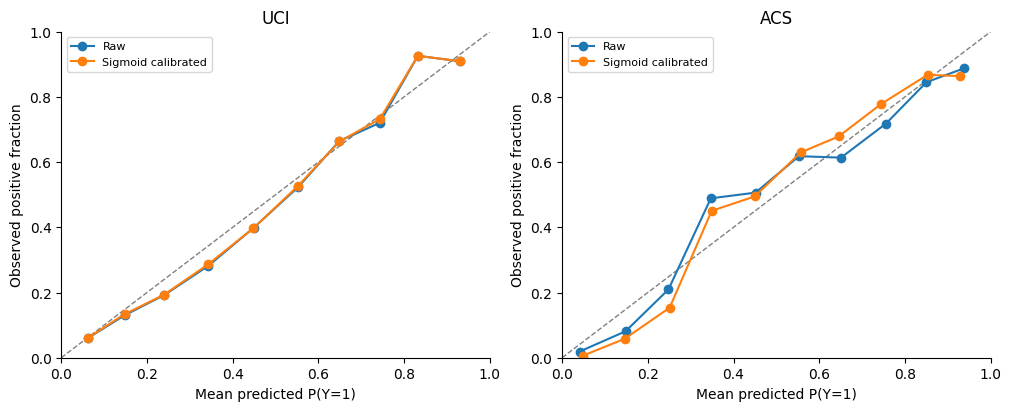

In [14]:
# Main step: assess probability calibration; these plots do not measure psychological trust.
fig,axes=plt.subplots(1,2,figsize=(10,4));frames=[]
for ax,(dataset,t) in zip(axes,PRIMARY.items()):
    ax.plot([0,1],[0,1],'--',color='gray',lw=1)
    for col,label in [('p_raw','Raw'),('p','Sigmoid calibrated')]:
        r=reliability(t.y,t[col]);r['dataset']=dataset;r['stage']=label;frames.append(r)
        ax.plot(r.predicted,r.observed,'o-',label=label)
    ax.set(title=dataset,xlabel='Mean predicted P(Y=1)',ylabel='Observed positive fraction',xlim=(0,1),ylim=(0,1));ax.legend(fontsize=8)
export_fig(fig,'RQ1_F1_reliability','Fixed-bin held-out reliability. Bin counts in companion CSV; no claim of individual probability certainty.',pd.concat(frames))

**7. RQ1 F2 — Map the value of context-aware decisions across stakes**  
**Methodology step / research connection:** M5–M6; RQ1 stakes and available alternatives

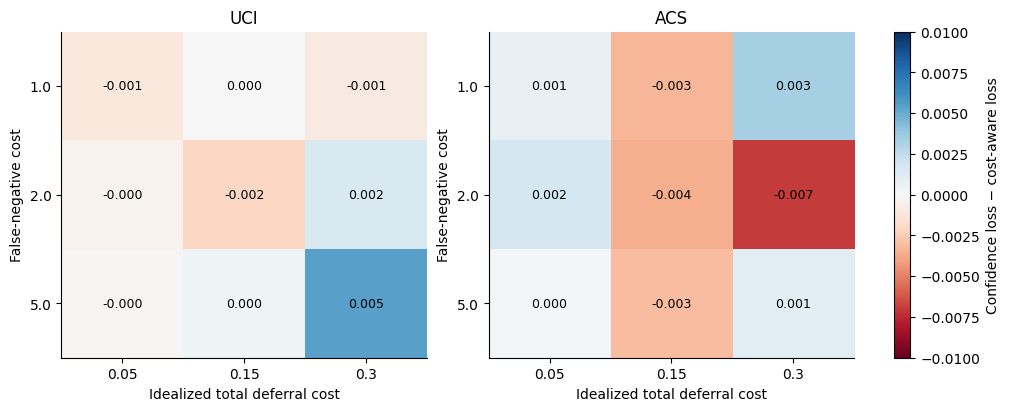

In [15]:
# Main step: vary only constructed decision costs; choose each confidence threshold on validation data.
rows=[];fns=[1.,2.,5.];ds=[.05,.15,.30]
for dataset,t in PRIMARY.items():
    v=VALID[dataset]
    for fn in fns:
        for d in ds:
            th=choose_threshold(v.y,v.p,fn,d)
            lc=case_loss(t.y,actions(t.p,'confidence',fn,d,th),fn,d)
            la=case_loss(t.y,actions(t.p,'cost_aware',fn,d),fn,d)
            rows.append(dict(dataset=dataset,fn=fn,defer_cost=d,confidence_threshold=th,
                             confidence_loss=lc.mean(),cost_aware_loss=la.mean(),advantage=(lc-la).mean()))
mapdf=pd.DataFrame(rows);fig,axes=plt.subplots(1,2,figsize=(10,4))
vmax=max(.01,abs(mapdf.advantage).max())
for ax,dataset in zip(axes,PRIMARY):
    tab=mapdf[mapdf.dataset==dataset].pivot(index='fn',columns='defer_cost',values='advantage')
    im=ax.imshow(tab.values,cmap='RdBu',vmin=-vmax,vmax=vmax,aspect='auto')
    ax.set(xticks=range(len(ds)),xticklabels=ds,yticks=range(len(fns)),yticklabels=fns,
           xlabel='Idealized total deferral cost',ylabel='False-negative cost',title=dataset)
    for i in range(len(fns)):
        for j in range(len(ds)):ax.text(j,i,f'{tab.values[i,j]:.3f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=list(axes),label='Confidence loss − cost-aware loss')
export_fig(fig,'RQ1_F2_stakes_map','Positive values favor cost-aware abstention. Costs are scenarios; finite-test differences need not favor either method.',mapdf)

**8. RQ1 T1 — Compare held-out policies and paired loss differences**  
**Methodology step / research connection:** M6 and M10; RQ1 primary performance comparison

In [16]:
# Main step: bootstrap paired test-cluster loss differences, conditional on fitted models and fixed scenario costs.
rows=[];sensitivity=[]
for dataset,t in PRIMARY.items():
    baseline=case_loss(t.y,actions(t.p,'confidence',threshold=THRESH[dataset]))
    for label in ['forced_05','forced_cost','confidence','cost_aware']:
        a=actions(t.p,label,threshold=THRESH[dataset]);loss=case_loss(t.y,a)
        dl,dh=cluster_ci(loss-baseline,t.cluster)
        rows.append(dict(dataset=dataset,policy=label,**summary(t.y,t.p,a,t.cluster),
                         delta_vs_confidence=(loss-baseline).mean(),delta_low=dl,delta_high=dh))
    for seed in CFG['seeds']:
        tt=STORED[dataset,seed,'test'];vv=STORED[dataset,seed,'val'];th=choose_threshold(vv.y,vv.p)
        for label in ['forced_05','forced_cost','confidence','cost_aware','fixed_08','constant_majority']:
            if label=='fixed_08':a=actions(tt.p,'confidence',threshold=.8)
            elif label=='constant_majority':
                train_y=DATA[dataset]['y'][SPLITS[dataset,seed]['train']]
                a=np.full(len(tt),int(train_y.mean()>=.5))
            else:a=actions(tt.p,label,threshold=th)
            sensitivity.append(dict(dataset=dataset,seed=seed,model=FITS[dataset,seed][2],policy=label,
                                    loss=case_loss(tt.y,a).mean(),coverage=(a!=-1).mean()))
export_table(pd.DataFrame(rows),'RQ1_T1_policy_comparison','Primary scenario FN=5, FP=1, idealized total defer cost=.15. Delta <0 favors the row policy over confidence abstention; paired cluster-bootstrap 95% intervals.')
export_table(pd.DataFrame(sensitivity),'S05_split_seed_sensitivity','All split seeds and supporting baselines; not independent replications of a population study.',False)

,dataset,policy,loss,loss_low,loss_high,coverage,accepted_n,selective_error,delta_vs_confidence,delta_low,delta_high
0,UCI,forced_05,0.679440,0.639387,0.728842,1.000000,6002,0.168944,0.529182,0.489524,0.579252
1,UCI,forced_cost,0.554149,0.529209,0.582899,1.000000,6002,0.366211,0.403890,0.378977,0.432790
2,UCI,confidence,0.150258,0.149262,0.152002,0.003832,23,0.043478,0.000000,0.000000,0.000000
3,UCI,cost_aware,0.149867,0.146713,0.153886,0.035322,212,0.033019,-0.000392,-0.003323,0.003571
4,ACS,forced_05,0.750531,0.652238,0.837225,1.000000,942,0.223992,0.614119,0.519280,0.703792
5,ACS,forced_cost,0.392781,0.360154,0.427807,1.000000,942,0.363057,0.256369,0.229364,0.288805
6,ACS,confidence,0.136412,0.121765,0.155966,0.225053,212,0.033019,0.000000,0.000000,0.000000
7,ACS,cost_aware,0.139490,0.134045,0.144588,0.112527,106,0.056604,0.003079,-0.015397,0.017316


,dataset,seed,model,policy,loss,coverage
0,UCI,42,RF,forced_05,0.679440,1.000000
1,UCI,42,RF,forced_cost,0.554149,1.000000
2,UCI,42,RF,confidence,0.150258,0.003832
3,UCI,42,RF,cost_aware,0.149867,0.035322
4,UCI,42,RF,fixed_08,0.384247,0.640953
5,UCI,42,RF,constant_majority,1.023825,1.000000
6,UCI,43,RF,forced_05,0.753956,1.000000
7,UCI,43,RF,forced_cost,0.544061,1.000000
8,UCI,43,RF,confidence,0.150433,0.002665
9,UCI,43,RF,cost_aware,0.151458,0.042479


**9. RQ1 T2 — Find action reversals at unchanged confidence**  
**Methodology step / research connection:** M6; RQ1 counterexamples connecting predictions to actions

In [17]:
# Main step: match the same held-out cases across prespecified contexts, keeping their probabilities unchanged.
rows=[]
for dataset,t in PRIMARY.items():
    p=t.p.to_numpy();a1=actions(p,'cost_aware',fn=1.,d=.30);a2=actions(p,'cost_aware',fn=5.,d=.30)
    bins=np.minimum((np.maximum(p,1-p)*10).astype(int),9)
    for b in sorted(np.unique(bins)):
        m=bins==b
        rows.append(dict(dataset=dataset,confidence_bin=f'[{b/10:.1f},{(b+1)/10:.1f}]',n=int(m.sum()),
                         mean_confidence=np.maximum(p[m],1-p[m]).mean(),
                         changed_action_rate=(a1[m]!=a2[m]).mean(),
                         defer_fn1=(a1[m]==-1).mean(),defer_fn5=(a2[m]==-1).mean()))
    examples=t.loc[a1!=a2,['record_id','p','y']].copy()
    examples['action_fn1']=a1[a1!=a2];examples['action_fn5']=a2[a1!=a2]
    examples.to_csv(OUT/'data'/f'RQ1_same_case_reversals_{dataset}.csv',index=False)
export_table(pd.DataFrame(rows),'RQ1_T2_same_confidence_reversals','Same cases and probabilities; FN cost changes from 1 to 5, FP=1, ideal defer=.30. This is a constructed decision contrast, not a causal effect on human reliance.')

,dataset,confidence_bin,n,mean_confidence,changed_action_rate,defer_fn1,defer_fn5
0,UCI,"[0.5,0.6]",470,0.552466,0.000000,1.0,1.000000
1,UCI,"[0.6,0.7]",637,0.653648,0.000000,1.0,1.000000
2,UCI,"[0.7,0.8]",1048,0.757324,0.843511,0.0,0.843511
3,UCI,"[0.8,0.9]",2282,0.852186,0.988168,0.0,0.988168
4,UCI,"[0.9,1.0]",1565,0.937380,0.571246,0.0,0.571246
5,ACS,"[0.5,0.6]",176,0.553393,0.000000,1.0,1.000000
6,ACS,"[0.6,0.7]",195,0.648495,0.000000,1.0,1.000000
7,ACS,"[0.7,0.8]",205,0.747118,0.604878,0.0,0.604878
8,ACS,"[0.8,0.9]",189,0.853794,0.640212,0.0,0.640212
9,ACS,"[0.9,1.0]",177,0.948414,0.322034,0.0,0.322034


**10. RQ2 F3 — Inspect subgroup reliability with sample counts**  
**Methodology step / research connection:** M7; RQ2 population evidence versus subgroup evidence

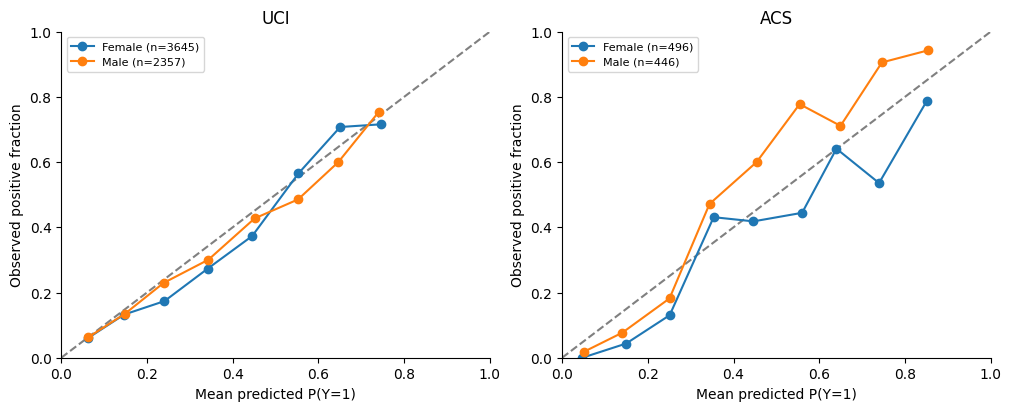

In [18]:
# Main step: audit recorded-sex groups in both tasks; retain race-category detail in the subgroup evidence table.
fig,axes=plt.subplots(1,2,figsize=(10,4));frames=[]
for ax,(dataset,t) in zip(axes,PRIMARY.items()):
    ax.plot([0,1],[0,1],'--',color='gray')
    for group,sub in t.groupby('sex'):
        if len(sub)<CFG['minimum_group_n']:continue
        r=reliability(sub.y,sub.p);r['dataset']=dataset;r['group']=group;frames.append(r)
        # Sparse bins remain in data but are omitted from plotted lines.
        plot=r[r.n>=20]
        ax.plot(plot.predicted,plot.observed,'o-',label=f'{group} (n={len(sub)})')
    ax.set(title=dataset,xlabel='Mean predicted P(Y=1)',ylabel='Observed positive fraction',xlim=(0,1),ylim=(0,1));ax.legend(fontsize=8)
export_fig(fig,'RQ2_F3_subgroup_reliability','Recorded-sex calibration; plotted bins require >=20 records. Full bin counts are exported. Group evidence is not a fairness verdict.',pd.concat(frames))

**11. RQ2 F4 — Compare subgroup error and coverage under a shared rule**  
**Methodology step / research connection:** M7; RQ2 unequal evidence across acceptance thresholds

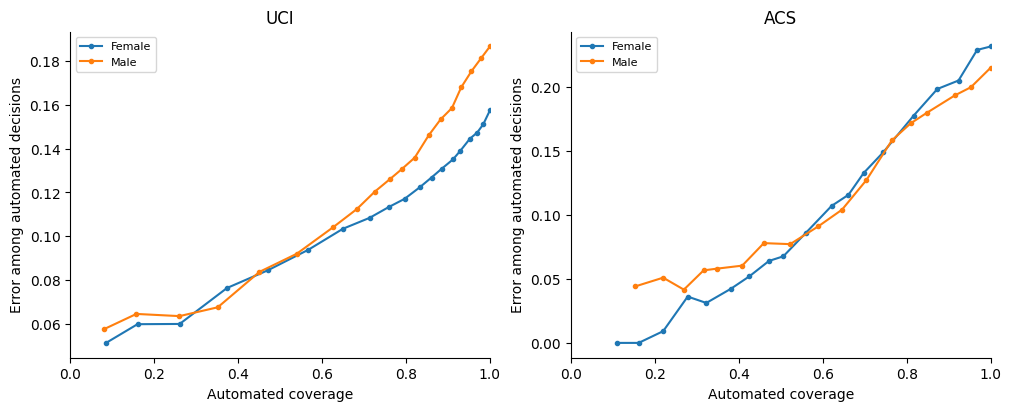

In [19]:
# Main step: describe test error–coverage profiles without selecting a threshold from test outcomes.
rows=[];fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(dataset,t) in zip(axes,PRIMARY.items()):
    for group,sub in t.groupby('sex'):
        if len(sub)<CFG['minimum_group_n']:continue
        pts=[]
        for th in np.linspace(.5,.95,19):
            a=actions(sub.p,'confidence',threshold=th);m=a!=-1
            err=float((a[m]!=sub.y.to_numpy()[m]).mean()) if m.sum()>=CFG['minimum_accepted_n'] else np.nan
            row=dict(dataset=dataset,group=group,threshold=th,coverage=m.mean(),accepted_n=int(m.sum()),selective_error=err)
            rows.append(row);pts.append(row)
        tab=pd.DataFrame(pts);ax.plot(tab.coverage,tab.selective_error,'o-',ms=3,label=group)
    ax.set(title=dataset,xlabel='Automated coverage',ylabel='Error among automated decisions',xlim=(0,1));ax.legend(fontsize=8)
export_fig(fig,'RQ2_F4_error_coverage','Descriptive shared-threshold paths; errors with fewer than 50 automated cases are suppressed. Thresholds are not chosen on these test curves.',pd.DataFrame(rows))

**12. RQ2 T3 — Quantify subgroup evidence and flag insufficient support**  
**Methodology step / research connection:** M7 and M10; RQ2 finite-sample warrant

In [20]:
# Main step: compute group loss intervals and suppress poorly supported accepted-case error estimates.
rows=[]
for dataset,t in PRIMARY.items():
    for attribute in (['sex','age_group','race'] if dataset=='ACS' else ['sex','age_group']):
        for group,sub in t.groupby(attribute):
            a=actions(sub.p,'confidence',threshold=THRESH[dataset]);m=a!=-1
            sufficient=len(sub)>=CFG['minimum_group_n'] and m.sum()>=CFG['minimum_accepted_n']
            error=float((a[m]!=sub.y.to_numpy()[m]).mean()) if sufficient else np.nan
            elo,ehi=cluster_ci((a[m]!=sub.y.to_numpy()[m]).astype(float),sub.cluster.to_numpy()[m]) if sufficient else (np.nan,np.nan)
            low,high=cluster_ci(case_loss(sub.y,a),sub.cluster) if len(sub)>=CFG['minimum_group_n'] else (np.nan,np.nan)
            rows.append(dict(dataset=dataset,attribute=attribute,group=group,n=len(sub),accepted_n=int(m.sum()),
                             coverage=m.mean(),ece=ece(sub.y,sub.p) if len(sub)>=CFG['minimum_group_n'] else np.nan,
                             selective_error=error,error_low=elo,error_high=ehi,loss=case_loss(sub.y,a).mean(),
                             loss_low=low,loss_high=high,evidence='adequate counts' if sufficient else 'insufficient counts'))
export_table(pd.DataFrame(rows),'RQ2_T3_subgroup_evidence','Primary shared confidence policy. Recorded categories retain source meanings. Adequate counts is an operational screen, not proof of reliability; ECE is descriptive and bin-dependent.')

,dataset,attribute,group,n,accepted_n,coverage,ece,selective_error,error_low,error_high,loss,loss_low,loss_high,evidence
0,UCI,sex,Female,3645,15,0.004115,0.026727,NaN,NaN,NaN,0.150754,0.149178,0.153479,insufficient counts
1,UCI,sex,Male,2357,8,0.003394,0.017233,NaN,NaN,NaN,0.149491,0.149109,0.149809,insufficient counts
2,UCI,age_group,Age <40,4175,19,0.004551,0.020335,NaN,NaN,NaN,0.150515,0.149119,0.152911,insufficient counts
3,UCI,age_group,Age >=40,1827,4,0.002189,0.022538,NaN,NaN,NaN,0.149672,0.149343,0.150000,insufficient counts
4,ACS,sex,Female,496,128,0.258065,0.078415,0.023438,0.000000,0.051037,0.125403,0.111475,0.151157,adequate counts
5,ACS,sex,Male,446,84,0.188341,0.105080,0.047619,0.011628,0.107821,0.148655,0.123533,0.185694,adequate counts
6,ACS,age_group,Age <40,386,139,0.360104,0.073476,0.007194,0.000000,0.021205,0.098575,0.090602,0.106487,adequate counts
7,ACS,age_group,Age >=40,556,73,0.131295,0.068758,0.082192,0.027397,0.151784,0.162680,0.137283,0.194266,adequate counts
8,ACS,race,American Indian alone,1,0,0.000000,NaN,NaN,NaN,NaN,0.150000,NaN,NaN,insufficient counts
9,ACS,race,Asian alone,41,13,0.317073,NaN,NaN,NaN,NaN,0.102439,NaN,NaN,insufficient counts


**13. RQ2 T4 — Test group-informed thresholds without test-label tuning**  
**Methodology step / research connection:** M7; RQ2 additional validation evidence

In [21]:
# Main step: derive sex-specific thresholds from validation data, shrinking toward the shared threshold.
rows=[]
for dataset,t in PRIMARY.items():
    v=VALID[dataset];shared=THRESH[dataset];a_shared=actions(t.p,'confidence',threshold=shared)
    a_group=a_shared.copy();thresholds={}
    for group,vg in v.groupby('sex'):
        n=len(vg)
        if n>=CFG['minimum_validation_group_n']:
            local=choose_threshold(vg.y,vg.p);weight=n/(n+200.)
            threshold=weight*local+(1-weight)*shared
        else:threshold=shared
        thresholds[group]=threshold
        mask=t.sex.eq(group).to_numpy();a_group[mask]=actions(t.p.to_numpy()[mask],'confidence',threshold=threshold)
    for group,sub in t.groupby('sex'):
        m=t.sex.eq(group).to_numpy();ys=t.y.to_numpy()[m];gr=t.cluster.to_numpy()[m]
        diff=case_loss(ys,a_group[m])-case_loss(ys,a_shared[m]);lo,hi=cluster_ci(diff,gr)
        rows.append(dict(dataset=dataset,group=group,validation_n=int(v.sex.eq(group).sum()),test_n=int(m.sum()),
                         shared_threshold=shared,group_threshold=thresholds.get(group,shared),
                         shared_loss=case_loss(ys,a_shared[m]).mean(),group_loss=case_loss(ys,a_group[m]).mean(),
                         delta=diff.mean(),delta_low=lo,delta_high=hi,
                         shared_coverage=(a_shared[m]!=-1).mean(),group_coverage=(a_group[m]!=-1).mean()))
export_table(pd.DataFrame(rows),'RQ2_T4_group_informed_thresholds','Sex-specific validation thresholds, prespecified shrinkage n/(n+200), fallback to shared threshold below 80 validation records. This is a diagnostic comparison, not a deployment recommendation.')

,dataset,group,validation_n,test_n,shared_threshold,group_threshold,shared_loss,group_loss,delta,delta_low,delta_high,shared_coverage,group_coverage
0,UCI,Female,1827,3645,0.99,0.990000,0.150754,0.150754,0.000000,0.000000,0.000000,0.004115,0.004115
1,UCI,Male,1171,2357,0.99,0.990000,0.149491,0.149491,0.000000,0.000000,0.000000,0.003394,0.003394
2,ACS,Female,228,496,0.88,0.880000,0.125403,0.125403,0.000000,0.000000,0.000000,0.258065,0.258065
3,ACS,Male,228,446,0.88,0.922617,0.148655,0.146300,-0.002354,-0.028174,0.012183,0.188341,0.114350


**14. RQ3 — Freeze source model and partition independent ACS target domains**  
**Methodology step / research connection:** M8; RQ3 natural geographic and temporal shift

In [22]:
# Main step: use target labels only for target recalibration; keep target test households disjoint.
SHIFT={};model,recal,kind=FITS['ACS',CFG['primary_seed']]
for name,data in TARGETS.items():
    ix=np.arange(len(data['y']));a,b=next(GroupShuffleSplit(n_splits=1,test_size=.6,random_state=814).split(ix,groups=data['meta'].cluster))
    assert set(data['meta'].iloc[a].cluster).isdisjoint(data['meta'].iloc[b].cluster)
    raw=model.predict_proba(data['X'])[:,1];source_p=recal.predict_proba(sigmoid_logit(raw))[:,1]
    target_p=calibrate(raw[a],data['y'][a],raw[b])
    tab=data['meta'].iloc[b].copy().reset_index(drop=True);tab['y']=data['y'][b]
    tab['p_source']=source_p[b];tab['p_target']=target_p;tab['p_raw']=raw[b]
    tab.to_csv(OUT/'data'/f'shift_predictions_{name.replace(" ","_")}.csv',index=False)
    SHIFT[name]=dict(test=tab,cal_raw=raw[a],cal_y=data['y'][a],cal_groups=data['meta'].iloc[a].cluster.to_numpy(),raw_test=raw[b])
    print(name,'target recalibration pool:',len(a),'target test:',len(b))

ACS MD 2018 target recalibration pool: 4781 target test: 7219
ACS DE 2019 target recalibration pool: 1894 target test: 2861


**15. RQ3 T5 — Audit transported and recalibrated evidence**  
**Methodology step / research connection:** M8 and M10; RQ3 evidence restoration

In [23]:
# Main step: compare source-held-out and target performance; source confidence threshold remains fixed.
rows=[]
source=PRIMARY['ACS']
for domain,tab,stages in [('ACS DE 2018 (source)',source,[('source calibration','p')])]+[
    (name,obj['test'],[('source calibration','p_source'),('target recalibration','p_target')]) for name,obj in SHIFT.items()]:
    for stage,col in stages:
        p=tab[col]
        for policy in ['confidence','cost_aware']:
            a=actions(p,policy,threshold=THRESH['ACS'])
            rows.append(dict(domain=domain,stage=stage,policy=policy,**metrics(tab.y,p),**summary(tab.y,p,a,tab.cluster)))
transport=pd.DataFrame(rows)
export_table(transport,'RQ3_T5_transport_audit','ACS source DE 2018; targets MD 2018 and DE 2019. Same source-selected model and confidence threshold. Target sigmoid fit uses separate households; loss intervals condition on fitted calibration.')

,domain,stage,policy,n,prevalence,brier,ece,log_loss,auc,loss,loss_low,loss_high,coverage,accepted_n,selective_error
0,ACS DE 2018 (source),source calibration,confidence,942,0.395966,0.148627,0.062354,0.453244,0.866324,0.136412,0.121765,0.155966,0.225053,212,0.033019
1,ACS DE 2018 (source),source calibration,cost_aware,942,0.395966,0.148627,0.062354,0.453244,0.866324,0.139490,0.134045,0.144588,0.112527,106,0.056604
2,ACS MD 2018,source calibration,confidence,7219,0.485524,0.155676,0.067153,0.475782,0.865082,0.169934,0.158171,0.181594,0.251281,1814,0.055127
3,ACS MD 2018,source calibration,cost_aware,7219,0.485524,0.155676,0.067153,0.475782,0.865082,0.143212,0.138655,0.148502,0.135753,980,0.046939
4,ACS MD 2018,target recalibration,confidence,7219,0.485524,0.148998,0.015697,0.460103,0.865082,0.155576,0.146572,0.167662,0.308214,2225,0.058427
5,ACS MD 2018,target recalibration,cost_aware,7219,0.485524,0.148998,0.015697,0.460103,0.865082,0.140691,0.135170,0.146684,0.231057,1668,0.076139
6,ACS DE 2019,source calibration,confidence,2861,0.426424,0.156121,0.036216,0.478713,0.852073,0.174607,0.157327,0.193443,0.253058,724,0.059392
7,ACS DE 2019,source calibration,cost_aware,2861,0.426424,0.156121,0.036216,0.478713,0.852073,0.151258,0.142683,0.162512,0.117441,336,0.065476
8,ACS DE 2019,target recalibration,confidence,2861,0.426424,0.154222,0.015959,0.474894,0.852073,0.172667,0.155085,0.193402,0.293953,841,0.065398
9,ACS DE 2019,target recalibration,cost_aware,2861,0.426424,0.154222,0.015959,0.474894,0.852073,0.151992,0.141872,0.163463,0.175463,502,0.081673


**16. RQ3 F5 — Display decision loss under natural ACS transport**  
**Methodology step / research connection:** M8; RQ3 loss under frozen and refreshed calibration

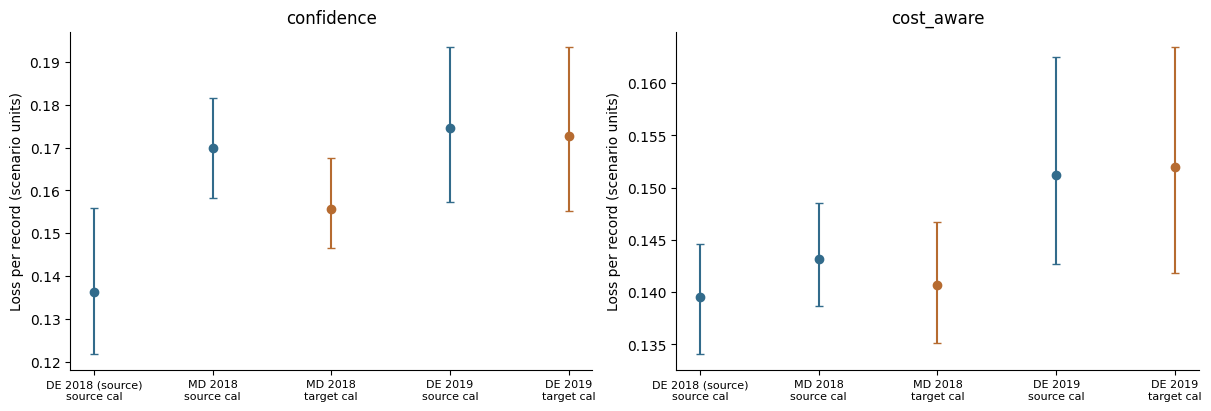

In [24]:
# Main step: show held-out policy losses and cluster-bootstrap intervals in each domain.
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,policy in zip(axes,['confidence','cost_aware']):
    tab=transport[transport.policy==policy].reset_index(drop=True);x=np.arange(len(tab))
    for j,row in tab.iterrows():
        ax.errorbar(j,row['loss'],yerr=[[row['loss']-row.loss_low],[row.loss_high-row['loss']]],fmt='o',capsize=3,color='#326b8b' if row.stage=='source calibration' else '#b66b30')
    ax.set(xticks=x,xticklabels=[r.domain.replace('ACS ','')+'\n'+('source cal' if r.stage=='source calibration' else 'target cal') for _,r in tab.iterrows()],ylabel='Loss per record (scenario units)',title=policy)
    ax.tick_params(axis='x',labelsize=8)
export_fig(fig,'RQ3_F5_natural_shift','Natural geographic and year-domain comparisons with paired-within-domain recalibration design. Between-domain differences are descriptive, not causal effects of state or year.',transport)

**17. RQ3 F6 — Stress-test UCI reliance under constructed population mixtures**  
**Methodology step / research connection:** M8; RQ3 explicit synthetic shift

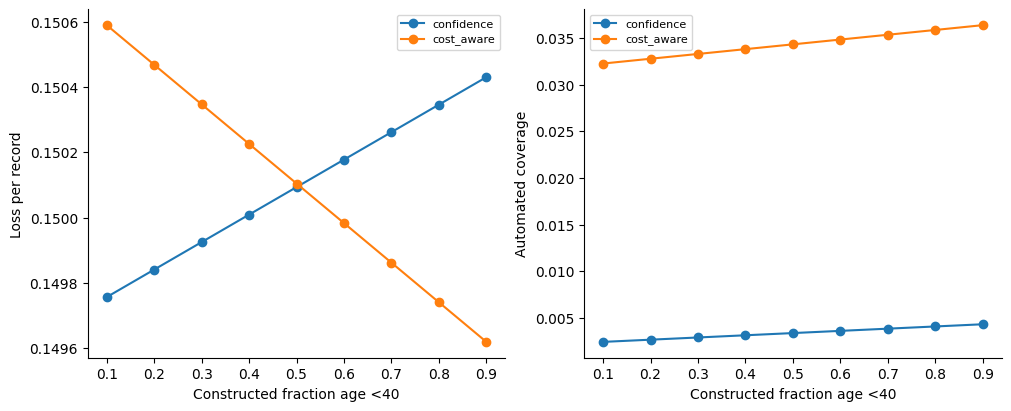

In [25]:
# Main step: reweight the held-out age mixture without inventing temporal UCI cohorts.
t=PRIMARY['UCI'];young=t.age_group.eq('Age <40').to_numpy();rows=[]
assert young.any() and (~young).any()
for share in np.linspace(.1,.9,9):
    w=np.where(young,share/young.sum(),(1-share)/(~young).sum())
    for policy in ['confidence','cost_aware']:
        a=actions(t.p,policy,threshold=THRESH['UCI']);l=case_loss(t.y,a)
        # Weighted ECE uses the same fixed probability bins.
        bins=np.minimum((t.p.to_numpy()*10).astype(int),9);wece=0.
        for b in np.unique(bins):
            m=bins==b;wece+=w[m].sum()*abs(np.average(t.y.to_numpy()[m],weights=w[m])-np.average(t.p.to_numpy()[m],weights=w[m]))
        rows.append(dict(young_share=share,policy=policy,loss=np.sum(w*l),ece=wece,coverage=np.sum(w*(a!=-1))))
mixture=pd.DataFrame(rows);fig,axes=plt.subplots(1,2,figsize=(10,4))
for policy,tab in mixture.groupby('policy'):
    axes[0].plot(tab.young_share,tab.loss,'o-',label=policy)
    axes[1].plot(tab.young_share,tab.coverage,'o-',label=policy)
for ax,label in zip(axes,['Loss per record','Automated coverage']):
    ax.set(xlabel='Constructed fraction age <40',ylabel=label);ax.legend(fontsize=8)
export_fig(fig,'RQ3_F6_constructed_mix','Synthetic UCI age-mixture reweighting of the same test sample. No claim of observed drift, causal age effects or new deployment data.',mixture)

**18. RQ3 T6 — Assess finite evidence for target recalibration**  
**Methodology step / research connection:** M8 and M10; RQ3 sample-size sensitivity

In [26]:
# Main step: vary target calibration evidence using nested random household samples; never use target test labels to fit.
rows=[]
for name,obj in SHIFT.items():
    tab=obj['test'];groups=obj['cal_groups'];unique=np.unique(groups)
    for repeat in range(5):
        ordered=np.random.default_rng(900+repeat).permutation(unique)
        for requested in [100,300,800]:
            # Household-complete samples may slightly exceed the requested person count.
            chosen=[];count=0
            for group in ordered:
                chosen.append(group);count+=np.sum(groups==group)
                if count>=requested:break
            m=np.isin(groups,chosen)
            if m.sum()<requested:continue
            p=calibrate(obj['cal_raw'][m],obj['cal_y'][m],obj['raw_test'])
            a=actions(p,'cost_aware')
            rows.append(dict(domain=name,requested_n=requested,actual_n=int(m.sum()),repeat=repeat,
                             brier=brier_score_loss(tab.y,p),ece=ece(tab.y,p),loss=case_loss(tab.y,a).mean(),coverage=(a!=-1).mean()))
sizes=pd.DataFrame(rows)
if sizes.empty:raise RuntimeError('Insufficient target calibration records for the planned analysis.')
sizes.to_csv(OUT/'data'/'RQ3_target_calibration_repetitions.csv',index=False)
size_summary=sizes.groupby(['domain','requested_n']).agg(repeats=('repeat','size'),actual_n_mean=('actual_n','mean'),
    brier_mean=('brier','mean'),brier_sd=('brier','std'),ece_mean=('ece','mean'),loss_mean=('loss','mean'),loss_sd=('loss','std'),coverage_mean=('coverage','mean')).reset_index()
export_table(size_summary,'RQ3_T6_recalibration_sample_size','Five nested household-order samples per target. SD describes recalibration-sample sensitivity, not a confidence interval. All rows use the same independent target test set.')

,domain,requested_n,repeats,actual_n_mean,brier_mean,brier_sd,ece_mean,loss_mean,loss_sd,coverage_mean
0,ACS DE 2019,100,5,100.2,0.155962,0.000818,0.039437,0.152884,0.001543,0.205872
1,ACS DE 2019,300,5,300.6,0.155014,0.000775,0.030674,0.151363,0.003857,0.185250
2,ACS DE 2019,800,5,800.2,0.154410,0.000217,0.020346,0.151573,0.001285,0.168473
3,ACS MD 2018,100,5,100.0,0.152767,0.003039,0.051384,0.143205,0.003620,0.301842
4,ACS MD 2018,300,5,300.6,0.149755,0.000930,0.025377,0.140680,0.000751,0.240366
5,ACS MD 2018,800,5,800.2,0.149293,0.000429,0.020960,0.140551,0.000462,0.225710


**19. Define explicit imperfect fallback and capacity-constrained policies**  
**Methodology step / research connection:** M9; RQ4 review assumptions

In [27]:
# Main step: compute expected fallback loss analytically instead of simulating human decisions.
def fallback_vector(y,error,review_cost,fn=5.):
    # Error is assumed symmetric and independent of X conditional on Y.
    y=np.asarray(y)
    return review_cost+error*np.where(y==1,fn,CFG['fp'])

def review_policy(p,policy,error=.1,review_cost=.05,threshold=.8,capacity=1.,fn=5.):
    p=np.asarray(p);fp=CFG['fp'];forced=actions(p,'forced_cost',fn=fn)
    predicted_auto=np.minimum(fn*p,fp*(1-p))
    predicted_fallback=review_cost+error*(fn*p+fp*(1-p))
    if policy=='no_review':return forced
    if policy=='confidence_review':
        a=actions(p,'confidence',fn=fn,threshold=threshold)
        candidates=np.where(a==-1)[0];scores=1-np.maximum(p,1-p)
    elif policy=='fallback_aware':
        a=forced.copy();candidates=np.where(predicted_auto>predicted_fallback)[0]
        scores=predicted_auto-predicted_fallback
    else:raise ValueError(policy)
    # Batch-level capacity is assumed known; selection uses probabilities only, not labels.
    limit=int(np.floor(capacity*len(p)));rank=candidates[np.argsort(-scores[candidates],kind='stable')]
    selected=rank[:limit]
    if policy=='confidence_review':
        # When review slots are unavailable, use cost-sensitive automated fallback.
        a[a==-1]=forced[a==-1]
    a[selected]=-1
    return a

def system_loss(y,a,error=.1,review_cost=.05,fn=5.):
    return np.where(a==-1,fallback_vector(y,error,review_cost,fn),case_loss(y,a,fn,0.))

# Mechanical checks for loss identities and valid actions, not empirical claims.
assert np.allclose(case_loss([0,1,0,1],[0,0,1,-1]),[0,5,1,.15])
assert np.allclose(fallback_vector([0,1],0,.05),[.05,.05])
assert set(actions(np.array([.01,.5,.99]),'cost_aware')).issubset({-1,0,1})
print('Fallback assumptions: symmetric class-conditional error; fixed per-review cost; no human performance data.')

Fallback assumptions: symmetric class-conditional error; fixed per-review cost; no human performance data.


**20. RQ4 F7 — Map when review improves over no review**  
**Methodology step / research connection:** M9; RQ4 fallback assumptions and conditional benefit

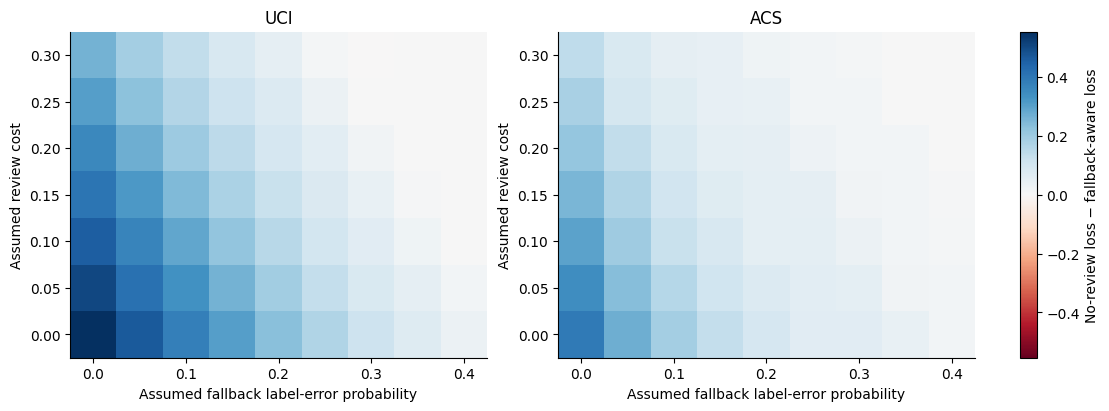

In [28]:
# Main step: retain possible negative empirical benefits; no-review is a prespecified comparison.
rows=[];errors=np.linspace(0,.4,9);costs=np.linspace(0,.3,7)
for dataset,t in PRIMARY.items():
    no=system_loss(t.y,review_policy(t.p,'no_review'))
    for err in errors:
        for cost in costs:
            a=review_policy(t.p,'fallback_aware',err,cost)
            l=system_loss(t.y,a,err,cost)
            rows.append(dict(dataset=dataset,error=err,review_cost=cost,advantage=(no-l).mean(),review_fraction=(a==-1).mean()))
fallback_map=pd.DataFrame(rows);fig,axes=plt.subplots(1,2,figsize=(11,4))
vmax=max(.01,abs(fallback_map.advantage).max())
for ax,dataset in zip(axes,PRIMARY):
    tab=fallback_map[fallback_map.dataset==dataset].pivot(index='review_cost',columns='error',values='advantage')
    im=ax.imshow(tab.values,origin='lower',aspect='auto',cmap='RdBu',vmin=-vmax,vmax=vmax,
                 extent=[errors.min()-.025,errors.max()+.025,costs.min()-.025,costs.max()+.025])
    ax.set(title=dataset,xlabel='Assumed fallback label-error probability',ylabel='Assumed review cost')
fig.colorbar(im,ax=list(axes),label='No-review loss − fallback-aware loss')
export_fig(fig,'RQ4_F7_fallback_map','Positive values favor fallback-aware review. Fallback performance and costs are constructed assumptions; losses integrate fallback error analytically.',fallback_map)

**21. RQ4 F8 — Trace system loss as fallback reliability deteriorates**  
**Methodology step / research connection:** M9; RQ4 abstention versus supported alternatives

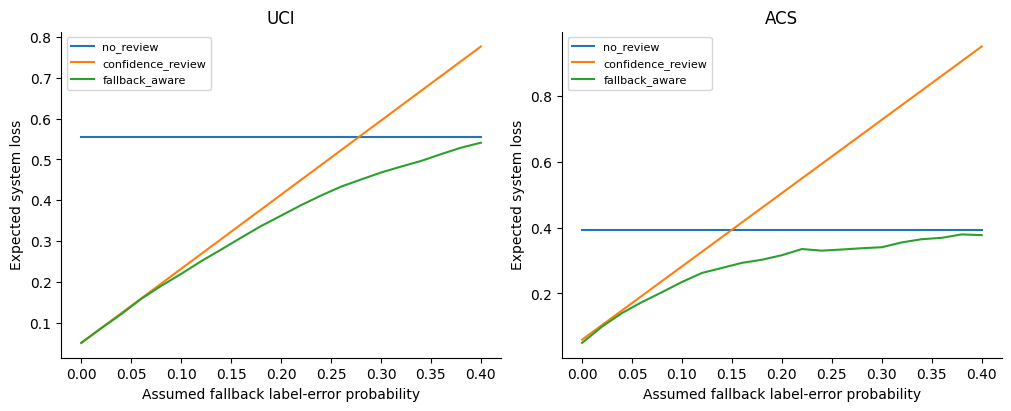

In [29]:
# Main step: evaluate frozen confidence referrals and a fallback-aware policy under the same assumed reviewer.
rows=[];fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(dataset,t) in zip(axes,PRIMARY.items()):
    for policy in ['no_review','confidence_review','fallback_aware']:
        for err in np.linspace(0,.4,21):
            a=review_policy(t.p,policy,err,CFG['review_cost'],THRESH[dataset])
            l=system_loss(t.y,a,err,CFG['review_cost'])
            rows.append(dict(dataset=dataset,policy=policy,error=err,loss=l.mean(),review_fraction=(a==-1).mean()))
        tab=pd.DataFrame(rows);tab=tab[(tab.dataset==dataset)&(tab.policy==policy)]
        ax.plot(tab.error,tab.loss,label=policy)
    ax.set(title=dataset,xlabel='Assumed fallback label-error probability',ylabel='Expected system loss');ax.legend(fontsize=8)
export_fig(fig,'RQ4_F8_fallback_sensitivity','Review cost=.05. Confidence threshold comes from the idealized primary scenario and stays fixed, exposing its transport to an imperfect fallback. Fallback-aware decisions use the stated scenario.',pd.DataFrame(rows))

**22. RQ4 T7 — Compare system policies under an imperfect fallback**  
**Methodology step / research connection:** M9 and M10; RQ4 primary fallback comparison

In [30]:
# Main step: report paired uncertainty over test clusters, conditional on the fallback model.
rows=[]
for dataset,t in PRIMARY.items():
    no=system_loss(t.y,review_policy(t.p,'no_review'),CFG['fallback_error'],CFG['review_cost'])
    for policy in ['no_review','confidence_review','fallback_aware']:
        a=review_policy(t.p,policy,CFG['fallback_error'],CFG['review_cost'],THRESH[dataset])
        l=system_loss(t.y,a,CFG['fallback_error'],CFG['review_cost']);lo,hi=cluster_ci(l,t.cluster)
        dl,dh=cluster_ci(l-no,t.cluster);m=a!=-1
        rows.append(dict(dataset=dataset,policy=policy,system_loss=l.mean(),loss_low=lo,loss_high=hi,
                         review_fraction=(~m).mean(),automated_error=(a[m]!=t.y.to_numpy()[m]).mean() if m.any() else np.nan,
                         delta_vs_no_review=(l-no).mean(),delta_low=dl,delta_high=dh))
export_table(pd.DataFrame(rows),'RQ4_T7_imperfect_fallback','Primary assumed reviewer error=.10, review cost=.05, FN=5, FP=1. Intervals do not incorporate uncertainty about assumed reviewer error. These are expected scenario losses, not observed human outcomes.')

,dataset,policy,system_loss,loss_low,loss_high,review_fraction,automated_error,delta_vs_no_review,delta_low,delta_high
0,UCI,no_review,0.554149,0.529209,0.582899,0.000000,0.366211,0.000000,0.000000,0.000000
1,UCI,confidence_review,0.232098,0.227316,0.237143,0.996168,0.043478,-0.322051,-0.349368,-0.298225
2,UCI,fallback_aware,0.219627,0.213838,0.226425,0.883705,0.204871,-0.334522,-0.362209,-0.311375
3,ACS,no_review,0.392781,0.360154,0.427807,0.000000,0.363057,0.000000,0.000000,0.000000
4,ACS,confidence_review,0.282059,0.261582,0.307775,0.774947,0.033019,-0.110722,-0.146536,-0.076796
5,ACS,fallback_aware,0.234660,0.218972,0.249027,0.682590,0.177258,-0.158121,-0.191297,-0.126338


**23. RQ4 T8 — Test scarce-review capacity and unmet referral demand**  
**Methodology step / research connection:** M9; RQ4 institutional constraints

In [31]:
# Main step: allocate limited slots using model scores only; unreviewed records get an explicit automated decision.
rows=[]
for dataset,t in PRIMARY.items():
    err,cost=CFG['fallback_error'],CFG['review_cost']
    no=system_loss(t.y,review_policy(t.p,'no_review'),err,cost)
    for policy in ['confidence_review','fallback_aware']:
        desired=review_policy(t.p,policy,err,cost,THRESH[dataset],1.)==-1
        for capacity in [0.,.05,.10,.20,.40,1.]:
            a=review_policy(t.p,policy,err,cost,THRESH[dataset],capacity)
            l=system_loss(t.y,a,err,cost);dl,dh=cluster_ci(l-no,t.cluster)
            rows.append(dict(dataset=dataset,policy=policy,capacity=capacity,
                             requested_fraction=desired.mean(),reviewed_fraction=(a==-1).mean(),
                             unmet_fraction=(desired & (a!=-1)).mean(),system_loss=l.mean(),
                             delta_vs_no_review=(l-no).mean(),delta_low=dl,delta_high=dh))
export_table(pd.DataFrame(rows),'RQ4_T8_review_capacity','Fixed batch review capacity; excess referrals receive cost-sensitive automation. Review demand is model/scenario-derived, not measured institutional workload. Intervals condition on the fitted scores and allocation.')

,dataset,policy,capacity,requested_fraction,reviewed_fraction,unmet_fraction,system_loss,delta_vs_no_review,delta_low,delta_high
0,UCI,confidence_review,0.00,0.996168,0.000000,0.996168,0.554149,0.000000,0.000000,0.000000
1,UCI,confidence_review,0.05,0.996168,0.049983,0.946185,0.544319,-0.009830,-0.013365,-0.005736
2,UCI,confidence_review,0.10,0.996168,0.099967,0.896201,0.533789,-0.020360,-0.025764,-0.013896
3,UCI,confidence_review,0.20,0.996168,0.199933,0.796235,0.509930,-0.044219,-0.051517,-0.034013
4,UCI,confidence_review,0.40,0.996168,0.399867,0.596301,0.413462,-0.140686,-0.153742,-0.127875
5,UCI,confidence_review,1.00,0.996168,0.996168,0.000000,0.232098,-0.322051,-0.349368,-0.298225
6,UCI,fallback_aware,0.00,0.883705,0.000000,0.883705,0.554149,0.000000,0.000000,0.000000
7,UCI,fallback_aware,0.05,0.883705,0.049983,0.833722,0.525125,-0.029024,-0.034758,-0.023196
8,UCI,fallback_aware,0.10,0.883705,0.099967,0.783739,0.493769,-0.060380,-0.068509,-0.051975
9,UCI,fallback_aware,0.20,0.883705,0.199933,0.683772,0.441186,-0.112962,-0.125414,-0.100372


## Interpretation rules for the manuscript

- **RQ1:** use reliability and decision-policy contrasts to distinguish evidence for a predictive proposition from justification for an action. Do not interpret lower ECE as proof of warranted reliance. A null or reversed loss advantage remains reportable.
- **RQ2:** identify the reference class for reliability claims and discuss what sparse evidence permits one to claim. Group-specific policies may improve or worsen outcomes; evaluate proportionality, privacy and discrimination concerns separately from numerical loss.
- **RQ3:** explain when validation evidence remains relevant, and why recalibration may fail to restore discrimination or decision performance. Maryland/year comparisons are observational domains. The USD 50,000 target is nominal across years, so temporal differences also reflect target economics; no inflation or causal attribution is implied.
- **RQ4:** distinguish an algorithm's option to abstain from an institution's ability to provide an adequate alternative. Symmetric reviewer error and fixed review cost are sensitivity assumptions. Actual human review may be selective, asymmetric, correlated with AI errors and capacity-dependent; the benchmark cannot establish those properties.

**Conceptual work still required:** define epistemic versus practical warrant; justify or criticize expected-loss reasoning; explain how error costs should be chosen and whose interests they represent; address objections concerning reference classes, rights and accountability; and situate the argument against competing accounts of trust and reliance. Experiments cannot derive ethical obligations from labels alone.

**Limitations:** fixed baselines, bounded domains, historical labels, no causal identification, unweighted ACS, descriptive bin-based calibration, overlapping age/sex/race audits, finite calibration samples, conditional bootstrap intervals, and illustrative fallback assumptions. Main CIs condition on fitted models; split-seed tables address some additional fitting variability without constituting a full nested bootstrap. No p-values or post hoc significance claims are generated.

**25. Revised RQ2 — Build independent reliability evidence and interval-sensitive decisions**  
**Method / research connection:** Extension E1; revised RQ2. Independent evidence replaces the use of confidence intervals solely for reporting.

In [32]:
# Main step: compare point and interval policies using an independent reliability-evidence partition.
from sklearn.base import clone
UQ_ROWS=[];UQ_BIN_ROWS=[];UQ_ALL_PRED=[]
UQ_BINS=5
UQ_ALPHA=.05
UQ_FN=[1.,2.,5.]
UQ_DEFER=[.05,.15,.30]

def uq_bounds(y,p,groups):
    y=np.asarray(y);p=np.asarray(p);groups=np.asarray(groups)
    ids=np.minimum((p*UQ_BINS).astype(int),UQ_BINS-1);rows=[]
    for b in range(UQ_BINS):
        m=ids==b;n=int(m.sum())
        if n:
            q=float(y[m].mean())
            counts=pd.Series(groups[m]).value_counts().to_numpy()
            weights=counts/counts.sum()
            # Weighted Hoeffding over independent bounded cluster contributions.
            # Union bound over five fixed bins; no assumption of independent rows within a cluster.
            radius=np.sqrt(.5*np.sum(weights**2)*np.log(2*UQ_BINS/UQ_ALPHA))
            lo=max(0.,q-radius);hi=min(1.,q+radius)
            clusters=len(counts)
        else:q=.5;lo=0.;hi=1.;clusters=0
        rows.append(dict(bin=b,n=n,clusters=clusters,q=q,low=lo,high=hi,width=hi-lo))
    return pd.DataFrame(rows)

def uq_actions(p,bounds,fn,d):
    b=np.minimum((np.asarray(p)*UQ_BINS).astype(int),UQ_BINS-1)
    q=bounds.q.to_numpy()[b];lo=bounds.low.to_numpy()[b];hi=bounds.high.to_numpy()[b]
    # Same actions and cost assumptions; the only change is point versus interval evaluation.
    pt=np.argmin(np.column_stack([fn*q,CFG['fp']*(1-q),np.full(len(b),d)]),axis=1)
    robust=np.argmin(np.column_stack([fn*hi,CFG['fp']*(1-lo),np.full(len(b),d)]),axis=1)
    return np.where(pt==2,-1,pt),np.where(robust==2,-1,robust),b

for dataset,data in DATA.items():
    seed=CFG['primary_seed'];split=SPLITS[dataset,seed]
    train=split['train'];pool=split['cal'];test=split['test']
    fit_local,evidence_local=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=20261109).split(
        pool,groups=data['meta'].iloc[pool].cluster))
    fit_idx=pool[fit_local];evidence_idx=pool[evidence_local]
    assert set(data['meta'].iloc[fit_idx].cluster).isdisjoint(data['meta'].iloc[evidence_idx].cluster)
    # Fixed LR avoids original model-selection dependence on the held-out evidence labels.
    fixed=make_model(data['X'],data['cats'],'LR',seed).fit(data['X'].iloc[train],data['y'][train])
    raw_fit=fixed.predict_proba(data['X'].iloc[fit_idx])[:,1]
    sig=LogisticRegression(C=1e6,max_iter=1000).fit(sigmoid_logit(raw_fit),data['y'][fit_idx])
    pe=sig.predict_proba(sigmoid_logit(fixed.predict_proba(data['X'].iloc[evidence_idx])[:,1]))[:,1]
    pt=sig.predict_proba(sigmoid_logit(fixed.predict_proba(data['X'].iloc[test])[:,1]))[:,1]
    ye=data['y'][evidence_idx];yt=data['y'][test]
    ge=data['meta'].iloc[evidence_idx].cluster.to_numpy();gt=data['meta'].iloc[test].cluster.to_numpy()
    test_meta=data['meta'].iloc[test].copy().reset_index(drop=True)
    test_meta['y']=yt;test_meta['p_fixed_LR']=pt
    test_meta.to_csv(OUT/'data'/f'UQ_test_predictions_{dataset}.csv',index=False)
    audit=data['meta'].iloc[pool][['record_id','cluster']].copy()
    fit_set=set(fit_idx.tolist())
    audit['role']=['sigmoid_fit' if i in fit_set else 'reliability_evidence' for i in pool]
    audit.to_csv(OUT/'data'/f'UQ_evidence_split_{dataset}.csv',index=False)
    sizes=[v for v in [50,100,250] if v<len(evidence_idx)]+[len(evidence_idx)]
    for repeat in range(5):
        order=np.random.default_rng(860+repeat).permutation(np.unique(ge))
        for requested in sizes:
            chosen=[];count=0
            for g in order:
                chosen.append(g);count+=np.sum(ge==g)
                if count>=requested:break
            m=np.isin(ge,chosen);bounds=uq_bounds(ye[m],pe[m],ge[m])
            for row in bounds.to_dict('records'):
                UQ_BIN_ROWS.append(dict(dataset=dataset,requested_n=requested,evidence_n=int(m.sum()),
                                        repeat=repeat,full_evidence=requested==len(evidence_idx),**row))
            for fn in UQ_FN:
                for d in UQ_DEFER:
                    point,interval,bin_id=uq_actions(pt,bounds,fn,d)
                    lp=case_loss(yt,point,fn,d);li=case_loss(yt,interval,fn,d)
                    lo,hi=cluster_ci(li-lp,gt) if requested==len(evidence_idx) and repeat==0 else (np.nan,np.nan)
                    UQ_ROWS.append(dict(dataset=dataset,requested_n=requested,evidence_n=int(m.sum()),repeat=repeat,
                        full_evidence=requested==len(evidence_idx),fn=fn,defer_cost=d,
                        point_loss=lp.mean(),interval_loss=li.mean(),delta=li.mean()-lp.mean(),delta_low=lo,delta_high=hi,
                        point_coverage=(point!=-1).mean(),interval_coverage=(interval!=-1).mean(),
                        changed_action_fraction=(point!=interval).mean(),
                        mean_interval_width=np.average(bounds.width,weights=np.bincount(bin_id,minlength=UQ_BINS))))
                    if requested==len(evidence_idx) and repeat==0:
                        detail=test_meta.copy();detail['bin']=bin_id;detail['point_action']=point;detail['interval_action']=interval
                        detail['fn']=fn;detail['defer_cost']=d;detail['dataset']=dataset
                        UQ_ALL_PRED.append(detail)
    print(dataset,'sigmoid-fit n:',len(fit_idx),'independent evidence n:',len(evidence_idx),'test n:',len(test))
UQ=pd.DataFrame(UQ_ROWS);UQ_BOUNDS=pd.DataFrame(UQ_BIN_ROWS)
UQ.to_csv(OUT/'data'/'UQ_all_repetitions.csv',index=False)
UQ_BOUNDS.to_csv(OUT/'data'/'UQ_bin_evidence_bounds.csv',index=False)
pd.concat(UQ_ALL_PRED,ignore_index=True).to_csv(OUT/'data'/'UQ_all_scenario_actions.csv',index=False)
print('Intervals assume independent clusters and stable evidence/test bin-average rates; they are not individual guarantees.')

UCI sigmoid-fit n: 3002 independent evidence n: 3002 test n: 6002
ACS sigmoid-fit n: 484 independent evidence n: 477 test n: 942
Intervals assume independent clusters and stable evidence/test bin-average rates; they are not individual guarantees.


**26. Revised RQ2 — Display policy comparisons and finite-evidence sensitivity**  
**Method / research connection:** Extension E2; revised RQ2, four new result objects with underlying data.

,dataset,requested_n,evidence_n,fn,defer_cost,point_loss,interval_loss,delta,delta_low,delta_high,point_coverage,interval_coverage,changed_action_fraction,mean_interval_width
27,UCI,3002,3002,1.0,0.05,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.109699
28,UCI,3002,3002,1.0,0.15,0.134439,0.150000,0.015561,0.008800,0.020150,0.475841,0.000000,0.475841,0.109699
29,UCI,3002,3002,1.0,0.30,0.163312,0.164012,0.000700,-0.000902,0.002201,0.892702,0.870377,0.022326,0.109699
30,UCI,3002,3002,2.0,0.05,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.109699
31,UCI,3002,3002,2.0,0.15,0.150000,0.150000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.109699
32,UCI,3002,3002,2.0,0.30,0.268177,0.300000,0.031823,0.018902,0.041746,0.498167,0.000000,0.498167,0.109699
33,UCI,3002,3002,5.0,0.05,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.109699
34,UCI,3002,3002,5.0,0.15,0.150000,0.150000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.109699
35,UCI,3002,3002,5.0,0.30,0.299300,0.300000,0.000700,-0.000902,0.002201,0.022326,0.000000,0.022326,0.109699
207,ACS,477,477,1.0,0.05,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.363485


,dataset,requested_n,fn,defer_cost,repetitions,actual_evidence_n,point_loss,interval_loss,delta_mean,delta_sd,point_coverage,interval_coverage,changed_action_fraction
0,ACS,50,1.0,0.05,5,50.4,0.059130,0.050000,-0.009130,0.000000,0.114650,0.000000,0.114650
1,ACS,50,1.0,0.15,5,50.4,0.145191,0.150000,0.004809,0.022160,0.214650,0.000000,0.214650
2,ACS,50,1.0,0.30,5,50.4,0.207049,0.300000,0.092951,0.023526,0.714650,0.000000,0.714650
3,ACS,50,2.0,0.05,5,50.4,0.059130,0.050000,-0.009130,0.000000,0.114650,0.000000,0.114650
4,ACS,50,2.0,0.15,5,50.4,0.152622,0.150000,-0.002622,0.011085,0.146709,0.000000,0.146709
5,ACS,50,2.0,0.30,5,50.4,0.266051,0.300000,0.033949,0.033483,0.278769,0.000000,0.278769
6,ACS,50,5.0,0.05,5,50.4,0.059130,0.050000,-0.009130,0.000000,0.114650,0.000000,0.114650
7,ACS,50,5.0,0.15,5,50.4,0.152622,0.150000,-0.002622,0.011085,0.146709,0.000000,0.146709
8,ACS,50,5.0,0.30,5,50.4,0.280913,0.300000,0.019087,0.000407,0.210828,0.000000,0.210828
9,ACS,100,1.0,0.05,5,100.4,0.055478,0.050000,-0.005478,0.005000,0.068790,0.000000,0.068790


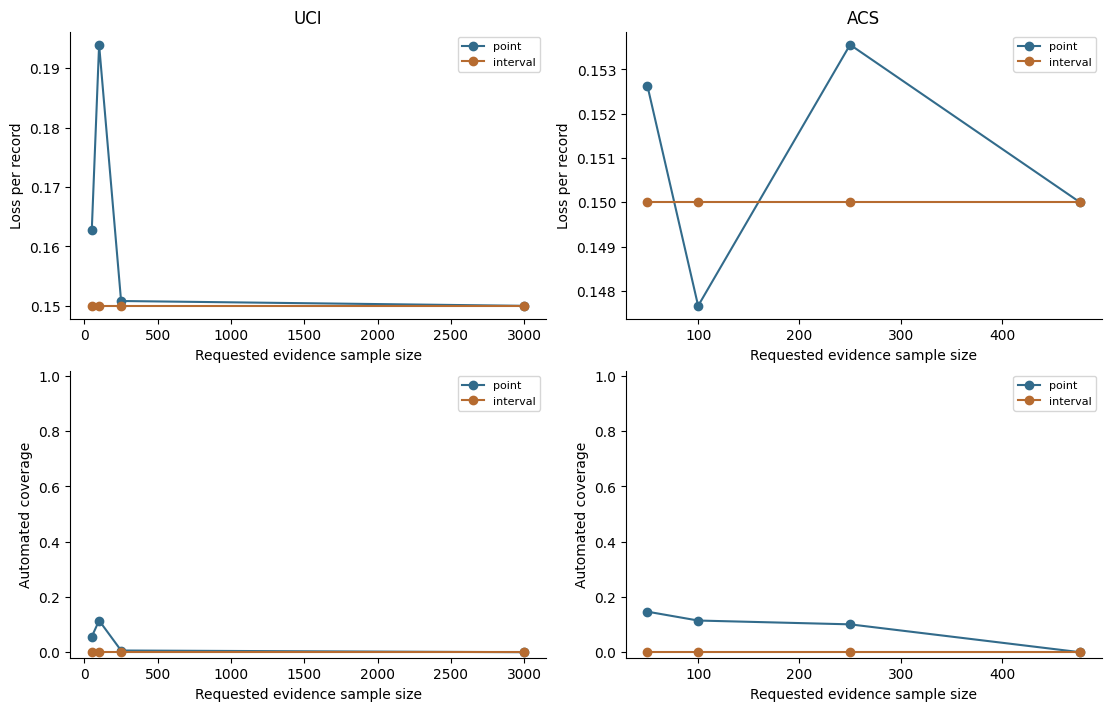

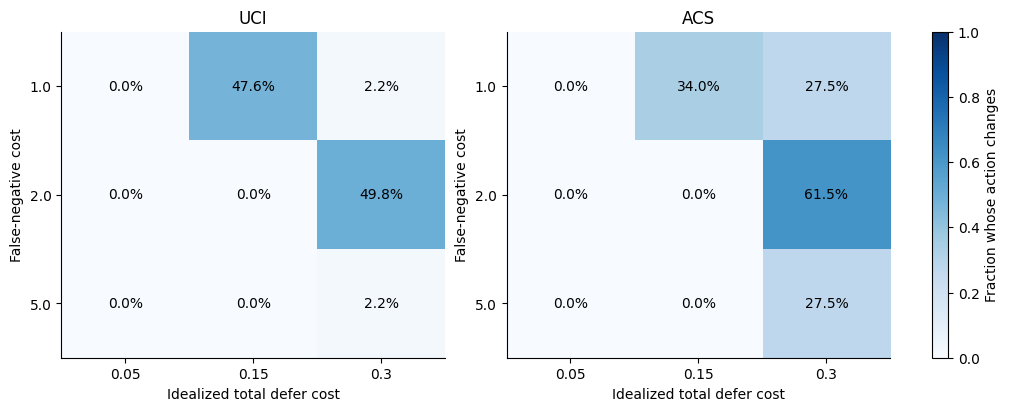

In [33]:
# Main step: display both improvements and failures; no policy superiority is assumed.
full=UQ[UQ.full_evidence & UQ.repeat.eq(0)].copy()
export_table(full.drop(columns=['repeat','full_evidence']), 'UQ_T1_interval_policy_audit',
    'Revised RQ2. Fixed LR; independent sigmoid-fitting and reliability-evidence partitions. Delta=interval minus point loss. Paired cluster-bootstrap 95% intervals condition on fitted evidence and model. Five-bin conservative intervals are used for bin-average risk, not individual probabilities.')
size_summary=UQ.groupby(['dataset','requested_n','fn','defer_cost']).agg(
    repetitions=('repeat','size'),actual_evidence_n=('evidence_n','mean'),point_loss=('point_loss','mean'),
    interval_loss=('interval_loss','mean'),delta_mean=('delta','mean'),delta_sd=('delta','std'),
    point_coverage=('point_coverage','mean'),interval_coverage=('interval_coverage','mean'),
    changed_action_fraction=('changed_action_fraction','mean')).reset_index()
export_table(size_summary,'UQ_T2_evidence_size_sensitivity',
    'Revised RQ2. Five nested cluster-order samples per evidence size and nine cost scenarios. SD is subsampling sensitivity, not a confidence interval. All configurations share an independent test set; exploratory design.')
main=UQ[UQ.fn.eq(5.) & UQ.defer_cost.eq(.15)]
fig,axes=plt.subplots(2,2,figsize=(11,7))
for col,dataset in enumerate(DATA):
    sub=main[main.dataset==dataset]
    tab=sub.groupby('requested_n').mean(numeric_only=True).reset_index()
    for policy,color in [('point','#326b8b'),('interval','#b66b30')]:
        axes[0,col].plot(tab.requested_n,tab[policy+'_loss'],'o-',label=policy,color=color)
        axes[1,col].plot(tab.requested_n,tab[policy+'_coverage'],'o-',label=policy,color=color)
    axes[0,col].set(title=dataset,ylabel='Loss per record',xlabel='Requested evidence sample size')
    axes[1,col].set(ylabel='Automated coverage',xlabel='Requested evidence sample size',ylim=(-.02,1.02))
    for row in range(2):axes[row,col].legend(fontsize=8)
export_fig(fig,'UQ_F1_evidence_size_loss_coverage',
    'Revised RQ2. FN=5, FP=1, idealized total deferral cost=.15. Lines average five evidence-order repetitions; no independent repeated-test claim.',main)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,dataset in zip(axes,DATA):
    tab=full[full.dataset==dataset].pivot(index='fn',columns='defer_cost',values='changed_action_fraction')
    im=ax.imshow(tab.values,aspect='auto',vmin=0,vmax=1,cmap='Blues')
    ax.set(title=dataset,xticks=range(len(tab.columns)),xticklabels=tab.columns,
           yticks=range(len(tab.index)),yticklabels=tab.index,xlabel='Idealized total defer cost',ylabel='False-negative cost')
    for i in range(len(tab.index)):
        for j in range(len(tab.columns)):ax.text(j,i,f'{tab.values[i,j]:.1%}',ha='center',va='center')
fig.colorbar(im,ax=list(axes),label='Fraction whose action changes')
export_fig(fig,'UQ_F2_interval_action_changes',
    'Revised RQ2. Same fixed-LR predictions and independent bin evidence; action changes arise from point versus interval loss evaluation. Conservative bounds can make deferral dominate.',full)

**27. Revised RQ4 — Audit group burdens under shared review capacity**  
**Method / research connection:** Extension E3; revised RQ4. Group summaries follow allocation over the full batch.

In [34]:
# Main step: measure group-specific outcomes of the same shared-capacity policy, not separate group quotas.
GB_ROWS=[];GB_GAP_ROWS=[]
for dataset,t in PRIMARY.items():
    y=t.y.to_numpy();p=t.p.to_numpy()
    for err in [0.,.10,.20]:
        cost=CFG['review_cost']
        for policy in ['confidence_review','fallback_aware']:
            desired=review_policy(p,policy,err,cost,THRESH[dataset],1.)==-1
            for capacity in [0.,.05,.10,.20,.40,1.]:
                a=review_policy(p,policy,err,cost,THRESH[dataset],capacity)
                loss=system_loss(y,a,err,cost)
                attributes=['sex','age_group']+(['race'] if dataset=='ACS' else [])
                sex_losses={};sex_masks={}
                for attribute in attributes:
                    for group in sorted(t[attribute].unique()):
                        m=t[attribute].eq(group).to_numpy();auto=m & (a!=-1);n=int(m.sum());accepted=int(auto.sum())
                        sufficient=n>=CFG['minimum_group_n'] and accepted>=CFG['minimum_accepted_n']
                        # Sparse group point burdens are retained with flags; unstable error estimates are suppressed.
                        lo,hi=cluster_ci(loss[m],t.cluster.to_numpy()[m]) if n>=CFG['minimum_group_n'] else (np.nan,np.nan)
                        GB_ROWS.append(dict(dataset=dataset,policy=policy,fallback_error=err,capacity=capacity,
                            attribute=attribute,group=group,n=n,automated_n=accepted,
                            requested_rate=desired[m].mean(),review_rate=(a[m]==-1).mean(),
                            unmet_rate=(desired[m] & (a[m]!=-1)).mean(),automated_coverage=(a[m]!=-1).mean(),
                            automated_error=(a[auto]!=y[auto]).mean() if sufficient else np.nan,
                            system_loss=loss[m].mean(),loss_low=lo,loss_high=hi,
                            evidence='adequate counts' if sufficient else 'sparse total or automated counts'))
                        if attribute=='sex':sex_losses[group]=loss[m];sex_masks[group]=m
                if 'Female' in sex_masks and 'Male' in sex_masks:
                    f=sex_masks['Female'];m=sex_masks['Male']
                    # Cluster resampling is performed jointly to preserve possible mixed-sex households.
                    clusters=t.cluster.to_numpy();unique=np.unique(clusters)
                    frame=pd.DataFrame({'cluster':clusters,'f_sum':loss*f,'m_sum':loss*m,
                                        'f_n':f.astype(int),'m_n':m.astype(int)})
                    agg=frame.groupby('cluster')[['f_sum','m_sum','f_n','m_n']].sum().to_numpy()
                    boot=[];rng=np.random.default_rng(482)
                    for _ in range(CFG['bootstrap']):
                        sampled=agg[rng.integers(0,len(agg),len(agg))].sum(axis=0)
                        if sampled[2]>0 and sampled[3]>0:boot.append(sampled[0]/sampled[2]-sampled[1]/sampled[3])
                    low,high=np.quantile(boot,[.025,.975])
                    GB_GAP_ROWS.append(dict(dataset=dataset,policy=policy,fallback_error=err,capacity=capacity,
                        female_n=int(f.sum()),male_n=int(m.sum()),
                        review_gap_female_minus_male=(a[f]==-1).mean()-(a[m]==-1).mean(),
                        unmet_gap_female_minus_male=(desired[f] & (a[f]!=-1)).mean()-(desired[m] & (a[m]!=-1)).mean(),
                        loss_gap_female_minus_male=loss[f].mean()-loss[m].mean(),gap_low=low,gap_high=high))
GB=pd.DataFrame(GB_ROWS);GB_GAPS=pd.DataFrame(GB_GAP_ROWS)
GB.to_csv(OUT/'data'/'GB_all_group_capacity_scenarios.csv',index=False)
GB_GAPS.to_csv(OUT/'data'/'GB_all_gap_scenarios.csv',index=False)
# Compact primary tables; full age/race/error scenarios remain in underlying CSV files.
primary_groups=GB[GB.attribute.eq('sex') & GB.fallback_error.eq(.10)]
export_table(primary_groups.drop(columns=['attribute','fallback_error']), 'GB_T1_group_capacity_audit',
    'Revised RQ4. Recorded-sex outcomes under shared capacity; assumed fallback error=.10 and review cost=.05. Deferral burden is operationalized as requests, actual review and unmet referrals, not observed delay or harm. Full age/race and fallback-error scenarios in data/GB_all_group_capacity_scenarios.csv.')
export_table(GB_GAPS[GB_GAPS.fallback_error.eq(.10)].drop(columns=['fallback_error']), 'GB_T2_sex_gap_audit',
    'Revised RQ4. Female minus male differences; signed gaps are not fairness verdicts. Joint cluster-bootstrap intervals for loss gaps condition on fitted scores, fixed batch allocation and assumed reviewer performance. The same reviewer error is assumed across groups.')

,dataset,policy,capacity,group,n,automated_n,requested_rate,review_rate,unmet_rate,automated_coverage,automated_error,system_loss,loss_low,loss_high,evidence
48,UCI,confidence_review,0.00,Female,3645,3645,0.995885,0.000000,0.995885,1.000000,0.366529,0.560768,0.528540,0.593307,adequate counts
49,UCI,confidence_review,0.00,Male,2357,2357,0.996606,0.000000,0.996606,1.000000,0.365719,0.543912,0.502804,0.584347,adequate counts
52,UCI,confidence_review,0.05,Female,3645,3490,0.995885,0.042524,0.953361,0.957476,0.358453,0.551509,0.518354,0.583602,adequate counts
53,UCI,confidence_review,0.05,Male,2357,2212,0.996606,0.061519,0.935087,0.938481,0.355787,0.533199,0.492004,0.572839,adequate counts
56,UCI,confidence_review,0.10,Female,3645,3323,0.995885,0.088340,0.907545,0.911660,0.350587,0.543676,0.510660,0.575039,adequate counts
57,UCI,confidence_review,0.10,Male,2357,2079,0.996606,0.117947,0.878659,0.882053,0.341510,0.518498,0.477868,0.560419,adequate counts
60,UCI,confidence_review,0.20,Female,3645,2972,0.995885,0.184636,0.811248,0.815364,0.326716,0.522126,0.491237,0.553077,adequate counts
61,UCI,confidence_review,0.20,Male,2357,1830,0.996606,0.223589,0.773017,0.776411,0.309290,0.491069,0.448637,0.535470,adequate counts
64,UCI,confidence_review,0.40,Female,3645,2220,0.995885,0.390947,0.604938,0.609053,0.181081,0.417051,0.382058,0.449107,adequate counts
65,UCI,confidence_review,0.40,Male,2357,1382,0.996606,0.413661,0.582944,0.586339,0.180897,0.407913,0.367453,0.455095,adequate counts


,dataset,policy,capacity,female_n,male_n,review_gap_female_minus_male,unmet_gap_female_minus_male,loss_gap_female_minus_male,gap_low,gap_high
12,UCI,confidence_review,0.00,3645,2357,0.000000,-0.000721,0.016856,-0.036673,0.074603
13,UCI,confidence_review,0.05,3645,2357,-0.018995,0.018274,0.018310,-0.031554,0.075097
14,UCI,confidence_review,0.10,3645,2357,-0.029606,0.028885,0.025178,-0.026443,0.080895
15,UCI,confidence_review,0.20,3645,2357,-0.038953,0.038232,0.031057,-0.019289,0.083921
16,UCI,confidence_review,0.40,3645,2357,-0.022715,0.021994,0.009138,-0.043341,0.063128
17,UCI,confidence_review,1.00,3645,2357,-0.000721,0.000000,-0.008171,-0.017164,0.000998
18,UCI,fallback_aware,0.00,3645,2357,0.000000,0.002720,0.016856,-0.036673,0.074603
19,UCI,fallback_aware,0.05,3645,2357,0.002662,0.000058,0.012868,-0.041555,0.067311
20,UCI,fallback_aware,0.10,3645,2357,-0.009346,0.012067,0.019885,-0.032600,0.070708
21,UCI,fallback_aware,0.20,3645,2357,0.010649,-0.007929,0.005083,-0.042272,0.051859


**28. Revised RQ4 — Display group review burdens and total decision loss**  
**Method / research connection:** Extension E4; revised RQ4, two figures with complete plotted data.

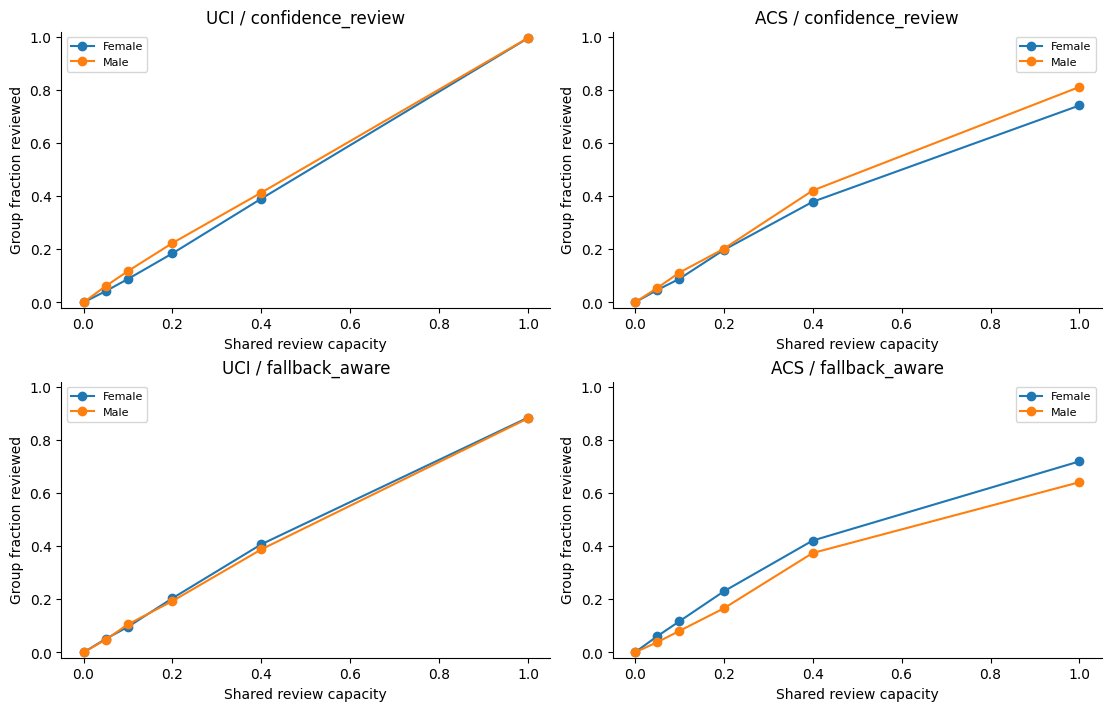

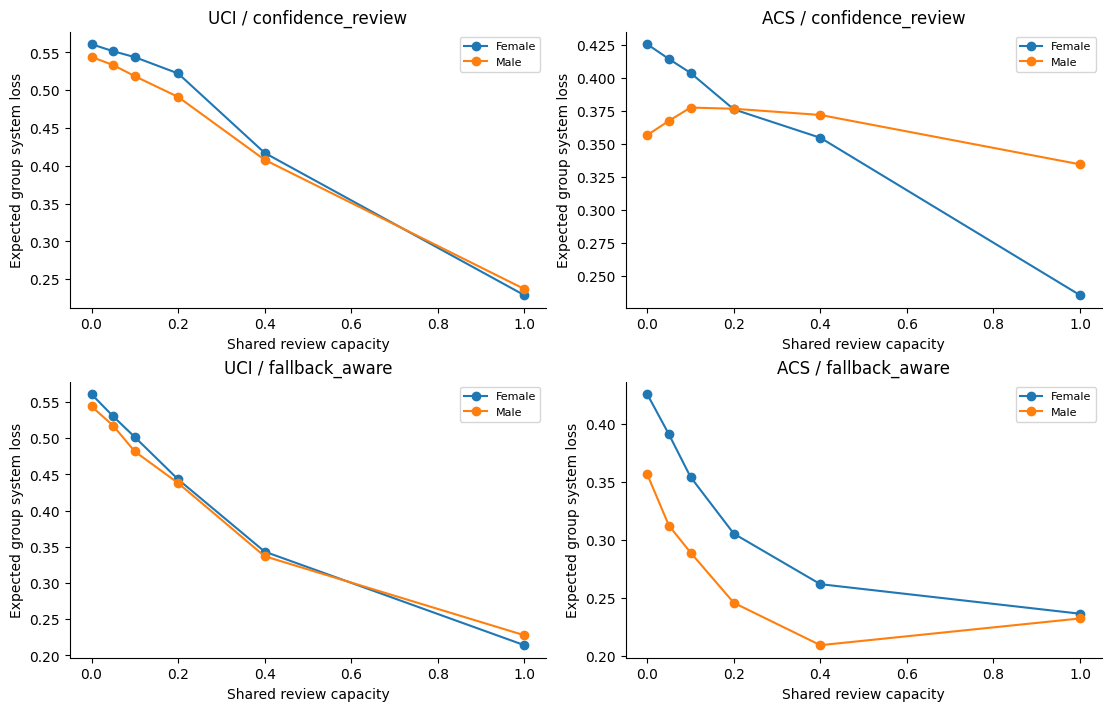

In [35]:
# Main step: show how review allocation and system loss differ across groups at the same total capacity.
plot=GB[GB.attribute.eq('sex') & GB.fallback_error.eq(.10)].copy()
fig,axes=plt.subplots(2,2,figsize=(11,7))
for col,dataset in enumerate(DATA):
    for row,policy in enumerate(['confidence_review','fallback_aware']):
        ax=axes[row,col]
        sub=plot[plot.dataset.eq(dataset)&plot.policy.eq(policy)]
        for group,tab in sub.groupby('group'):
            ax.plot(tab.capacity,tab.review_rate,'o-',label=group)
        ax.set(title=dataset+' / '+policy,xlabel='Shared review capacity',ylabel='Group fraction reviewed',ylim=(-.02,1.02))
        ax.legend(fontsize=8)
export_fig(fig,'GB_F1_group_review_capacity',
    'Revised RQ4. A group review rate can exceed the overall capacity fraction because slots are allocated over the complete batch, not equally within each group. Assumed fallback error=.10; no measured human behavior.',plot)
fig,axes=plt.subplots(2,2,figsize=(11,7))
for col,dataset in enumerate(DATA):
    for row,policy in enumerate(['confidence_review','fallback_aware']):
        ax=axes[row,col]
        sub=plot[plot.dataset.eq(dataset)&plot.policy.eq(policy)]
        for group,tab in sub.groupby('group'):
            ax.plot(tab.capacity,tab.system_loss,'o-',label=group)
        ax.set(title=dataset+' / '+policy,xlabel='Shared review capacity',ylabel='Expected group system loss')
        ax.legend(fontsize=8)
export_fig(fig,'GB_F2_group_system_loss',
    'Revised RQ4. Group expected system loss includes assumed fallback errors and review cost. Lines are descriptive; group CIs are in GB_T1. Differences do not establish discrimination or causal effects.',plot)

## Updated interpretation and submission boundaries

The revised questions now have explicit implemented analyses. Interpret whether interval-aware actions help, worsen, or simply defer more decisions from the actual UQ tables. Conservative intervals can rationally imply very little automation; that is a substantive limitation, not an error to conceal. In RQ4, error among automated records is selective and must be interpreted together with coverage, actual review and total system loss.

Independent calibration evidence, group-aware splits and explicit fallback assumptions improve technical scope. They do not establish a new theorem, a novel robust decision algorithm, moral warrant, psychological trust or publication acceptance. The five-bin Hoeffding intervals require independent clusters and stable bin-average outcome rates between evidence and test populations; they do not transfer automatically under shift. Bounds are conservative and do not quantify model misspecification or uncertain error costs. Subsampling repetitions are sensitivity analyses of the same dataset.

The prior proposal used California 2018 with a balanced sample; this notebook uses unbalanced, bounded ACS releases from Delaware 2018, Maryland 2018 and Delaware 2019. The revised proposal must state this scope accurately. Preserve the pilot as an earlier version and identify these additions as exploratory revision after feedback.

**24. Validate the full result package, save captions and create the ZIP**  
**Methodology step / research connection:** M11; all four RQs and reproducibility

In [36]:
# Main step: require all 24 primary results and their data exports before declaring a successful run.
expected=[f'RQ1_{x}' for x in ['F1_reliability','F2_stakes_map','T1_policy_comparison','T2_same_confidence_reversals']]+[
    f'RQ2_{x}' for x in ['F3_subgroup_reliability','F4_error_coverage','T3_subgroup_evidence','T4_group_informed_thresholds']]+[
    f'RQ3_{x}' for x in ['F5_natural_shift','F6_constructed_mix','T5_transport_audit','T6_recalibration_sample_size']]+[
    f'RQ4_{x}' for x in ['F7_fallback_map','F8_fallback_sensitivity','T7_imperfect_fallback','T8_review_capacity']]
expected += ['UQ_T1_interval_policy_audit','UQ_T2_evidence_size_sensitivity','UQ_F1_evidence_size_loss_coverage','UQ_F2_interval_action_changes','GB_T1_group_capacity_audit','GB_T2_sex_gap_audit','GB_F1_group_review_capacity','GB_F2_group_system_loss']
actual={r['id'] for r in RESULTS if r['primary']}
assert actual==set(expected),(set(expected)-actual,actual-set(expected))
for r in RESULTS:
    if r['kind']=='figure':
        for ext in ['pdf','png']:assert (OUT/'figures'/f'{r["id"]}.{ext}').stat().st_size>0
        assert (OUT/'data'/f'{r["id"]}_data.csv').stat().st_size>0
    else:
        for ext in ['pdf','csv']:assert (OUT/'tables'/f'{r["id"]}.{ext}').stat().st_size>0
pd.DataFrame(RESULTS).to_csv(OUT/'metadata/result_index.csv',index=False)
(OUT/'metadata/captions.md').write_text('\n\n'.join('**'+r['id']+'** '+r['caption'] for r in RESULTS))
versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'sklearn':sklearn.__version__,'matplotlib':matplotlib.__version__}
(OUT/'metadata/software_versions.json').write_text(json.dumps(versions,indent=2))
(OUT/'metadata/provenance.json').write_text(json.dumps(PROVENANCE,indent=2))
(OUT/'README.txt').write_text('Project 15 warranted reliance experiments.\n'
    'Twelve primary figures and twelve primary tables; supporting audits and predictions included.\n'
    'PDF figures are vector output; PNG figures are 300 dpi; tables have CSV and PDF copies.\n'
    'See metadata/captions.md for scope and assumptions. Costs and reviewer performance are scenarios.\n'
    'No human trust study or real-world deployment evaluation is claimed.\n'
    'UCI source: https://doi.org/10.24432/C55S3H (CC BY 4.0); Census PUMS releases via Census.gov.\n'
    'ACS task definition follows Folktables; sex, race and relationship predictors omitted.\n')
manifest=[]
for p in sorted(OUT.rglob('*')):
    if p.is_file() and p.name!='file_manifest.csv':
        manifest.append(dict(path=str(p.relative_to(OUT)),bytes=p.stat().st_size,sha256=hashlib.sha256(p.read_bytes()).hexdigest()))
pd.DataFrame(manifest).to_csv(OUT/'metadata/file_manifest.csv',index=False)
archive=BASE/'Project15_Revised_Results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():z.write(p,arcname=str(Path(OUT.name)/p.relative_to(OUT)))
with zipfile.ZipFile(archive) as z:assert z.testzip() is None
print('Validated:',len(actual),'primary results; archived files:',len(manifest)+1)
print('Archive:',archive,'| MB:',round(archive.stat().st_size/1e6,2))
display(FileLink(str(archive)))

Validated: 24 primary results; archived files: 129
Archive: /kaggle/working/Project15_Revised_Results.zip | MB: 6.43


/kaggle/working/Project15_Revised_Results.zip

## References and source attribution

1. Ferrario, A. (2026). *Being Pragmatic About Reliance and Trust in Artificial Intelligence*. Minds and Machines, 36, 5. https://doi.org/10.1007/s11023-025-09754-9
2. Minds and Machines. Aims and scope. https://link.springer.com/journal/11023/aims-and-scope
3. Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H. CC BY 4.0. Original prediction-method paper by Yeh and Lien (2009) is linked in the repository.
4. Ding, F., Hardt, M., Miller, J., & Schmidt, L. (2021). *Retiring Adult: New Datasets for Fair Machine Learning*. NeurIPS. Task documentation and code: https://github.com/socialfoundations/folktables. The loader directly reads Census PUMS and implements the documented ACSIncome filter and target, with an explicit predictor modification excluding sex, race and relationship.
5. US Census Bureau. ACS 1-Year PUMS, 2018 and 2019. https://www.census.gov/programs-surveys/acs/microdata.html. Original files and hashes are in the provenance output.
6. *Reliable Decisions with Threshold Calibration* (NeurIPS 2021). https://proceedings.neurips.cc/paper/2021/hash/0e65972dce68dad4d52d063967f0a705-Abstract.html
7. *Selective Omniprediction and Fair Abstention* (NeurIPS 2025). https://proceedings.neurips.cc/paper_files/paper/2025/hash/3826a7e2a07ee41ca42eaf57ed337df4-Abstract-Conference.html

**Before submission:** complete a focused related-work review, verify the claimed conceptual gap, preregister a final confirmatory specification if making confirmatory claims, and reassess figure selection and captions against actual results. This computational package supports a manuscript; it is not itself evidence that a manuscript meets acceptance standards.